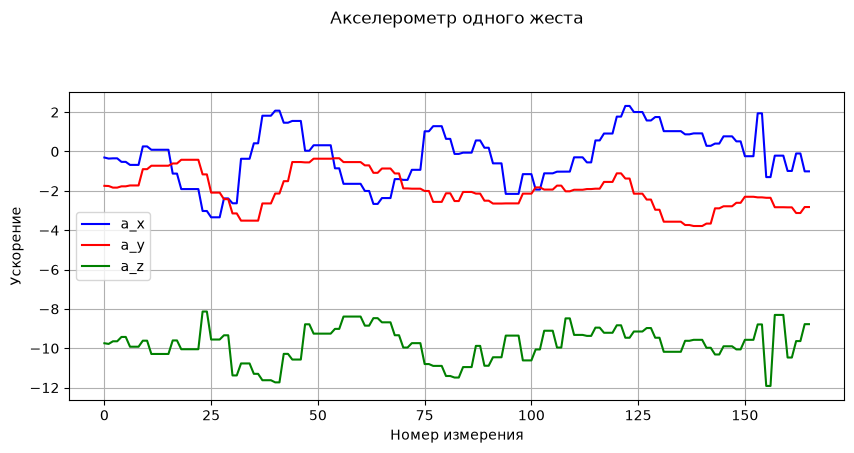

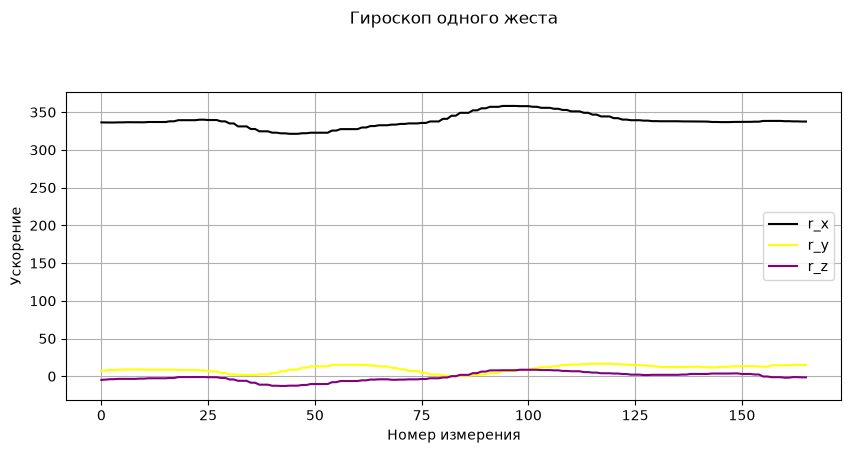

In [51]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew, sem
from scipy.signal import buttord, butter, sosfiltfilt
from scipy.ndimage import median_filter
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)
from sklearn.ensemble import IsolationForest


# собираем названия всех папок пользователй
dataset_root = Path(r"C:\Users\Даниил\IIT\task_1\data_legitimate")
user_folders = sorted([path for path in dataset_root.iterdir() if path.is_dir()])

# функция парсинга жеста из файла с номером num_file
# возвращает матрицу измерений (сигналов по горизонтали и временных рядов атрибутов по вертикали)
def get_gesture(user_folders, train_valid_test, num_user, num_file):
    # собираем итоговый путь
    result_path = user_folders[num_user] / "inf" / train_valid_test
    
    # определяем какого расширения хранятся файлы в папке
    txt_files_len = len(list(result_path.glob("*.txt")))
    json_files_len = len(list(result_path.glob("*.json")))
    if txt_files_len: txt_or_json = "*.txt" 
    else: txt_or_json = "*.json"
    
    # парсим все файлы (.txt или .json)
    gesture_files = sorted(result_path.glob(txt_or_json))
    
    # прочтали текстовый 0-ой файл как json-файл и записали его в виде словаря в file_data
    with open(gesture_files[num_file], "r", encoding = "utf-8") as file:
        file_data = json.load(file)

    if txt_or_json == "*.txt":
        # обращаемся к словарю по двум ключам и получаем все измерения
        measurements = file_data["params"]["data"]
        
        # создаем матрицу измерений размера (кол-во измерений) * 6
        time_series_matrix_list = []
        for measurement in measurements:
            # связываем конец первого и начало второго списков
            acceleration = measurement["acceleration"]
            rotation = measurement["rotation"]
            measurement_row = acceleration + rotation
            time_series_matrix_list.append(measurement_row)
    
    elif txt_or_json == "*.json":
        # будем парсить словарь измерений
        measurements = file_data
        
        # создаем матрицу измерений размера (кол-во измерений) * 6
        time_series_matrix_list = []
        for measurement in measurements:
            # связываем значения измерения в таком же порядке как и в txt
            if "x_rot" in measurement and "y_rot" in measurement and "z_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["x_rot"],
                                measurement["y_rot"], measurement["z_rot"]]
            elif "a_rot" in measurement and "b_rot" in measurement and "g_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["a_rot"],
                                measurement["b_rot"], measurement["g_rot"]]

            time_series_matrix_list.append(measurement_row)

    # преобразование типов из списка в numpy матричный класс
    time_series_matrix = np.array(time_series_matrix_list, dtype=float)
    return time_series_matrix

# парсим атрибуты (временные ряды) из матрицы для 0-ого файла
time_series_matrix = get_gesture(user_folders, "train", num_user=5, num_file=0)
a_x = time_series_matrix[:, 0]
a_y = time_series_matrix[:, 1]
a_z = time_series_matrix[:, 2]

r_x = np.unwrap(time_series_matrix[:, 3], period=360, axis=0)
r_y = np.unwrap(time_series_matrix[:, 4], period=360, axis=0)
r_z = np.unwrap(time_series_matrix[:, 5], period=360, axis=0)

# строим график временных рядов a_x, a_y, a_z (акселерометр)
plt.figure(figsize=(10, 4))

plt.plot(a_x, label="a_x", color="blue")
plt.plot(a_y, label="a_y", color="red")
plt.plot(a_z, label="a_z", color="green")

plt.title("Акселерометр одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

# строим график временных рядов r_x, r_y, r_z (гироскоп)
plt.figure(figsize=(10, 4))

plt.plot(r_x, label="r_x", color="black")
plt.plot(r_y, label="r_y", color="yellow")
plt.plot(r_z, label="r_z", color="purple")

plt.title("Гироскоп одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

Пытаюсь отфильтровать все 6 временных рядов в одном жесте (фильтр Баттерворта) и построить график для атрибута a_x

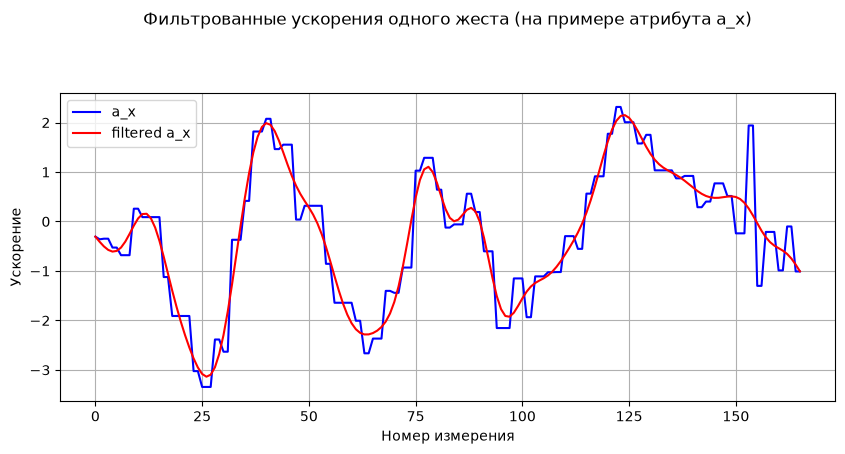

In [32]:
def butterworth_filter_gesture(time_series_matrix):
    wp = 0.17
    ws = 0.30
    gpass = 1
    gstop = 30

    order, cutoff = buttord(wp, ws, gpass, gstop)
    sos = butter(order, cutoff, btype="low", output="sos")
    filtered_matrix = sosfiltfilt(sos, time_series_matrix, axis=0)

    return filtered_matrix


filtered_time_series_matrix_bu = butterworth_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_bu[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

Теперь тоже самое, но реализуем уже медианнй фильтр и построить график для атрибута a_x

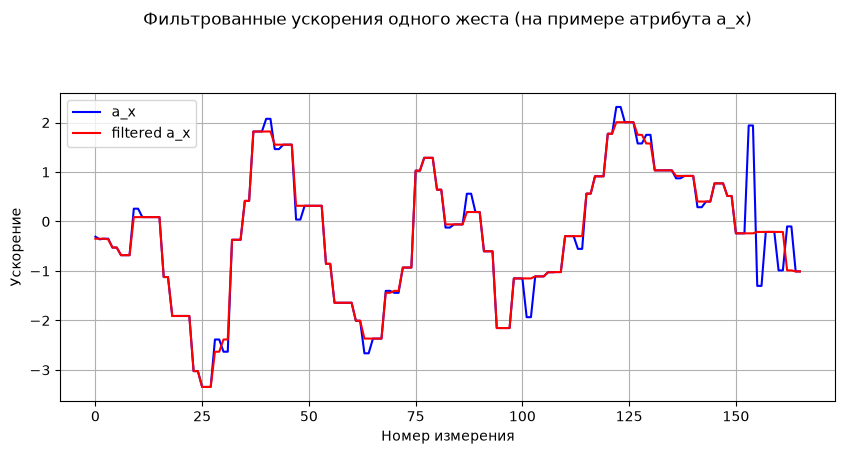

In [33]:
def median_filter_gesture(time_series_matrix, window_size=5):
    return median_filter(
        time_series_matrix,
        size=(window_size, 1)
    )


filtered_time_series_matrix_me = median_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_me[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()


Построим графики всех временных рядов одного пользователя

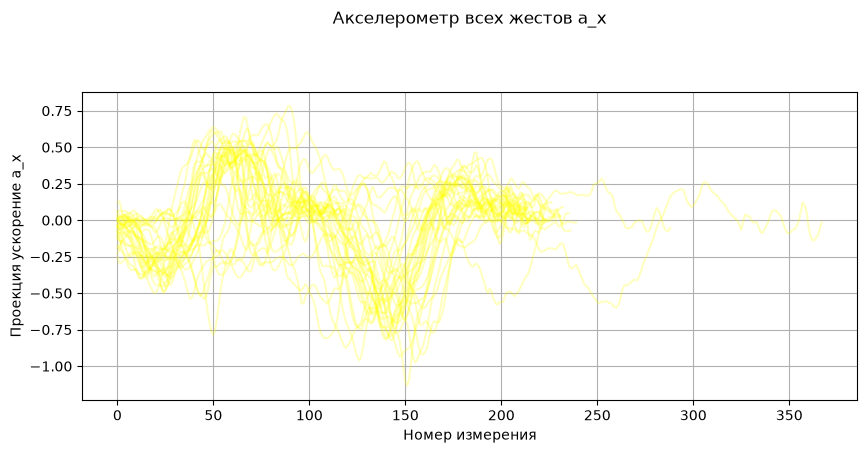

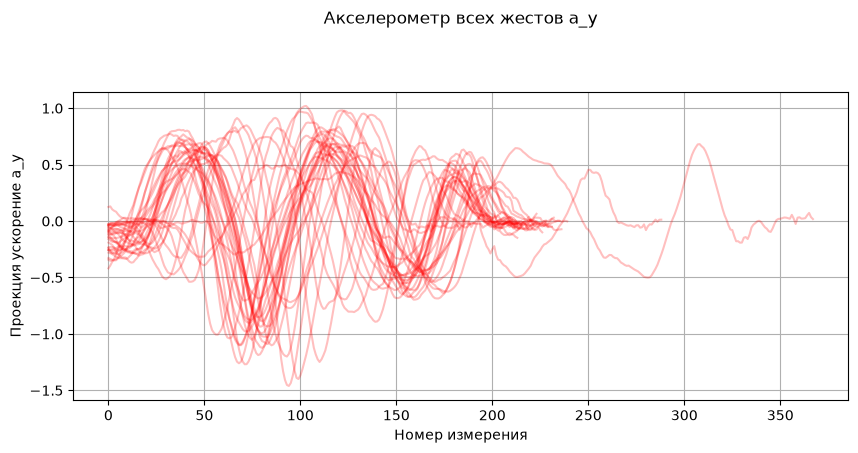

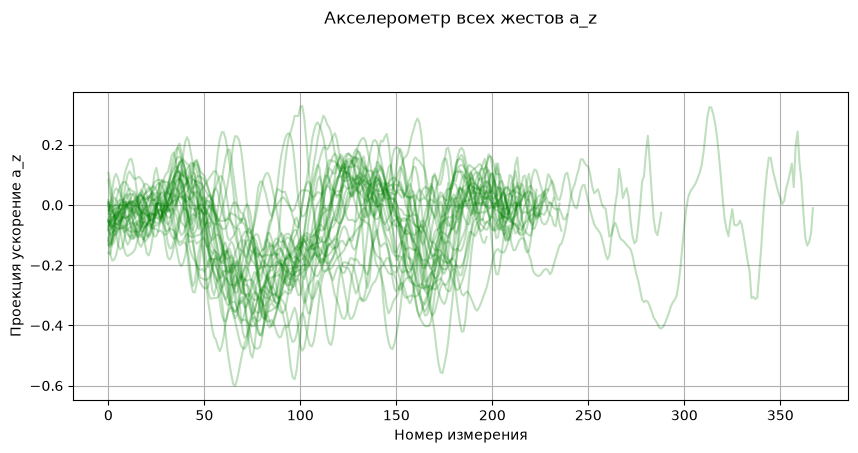

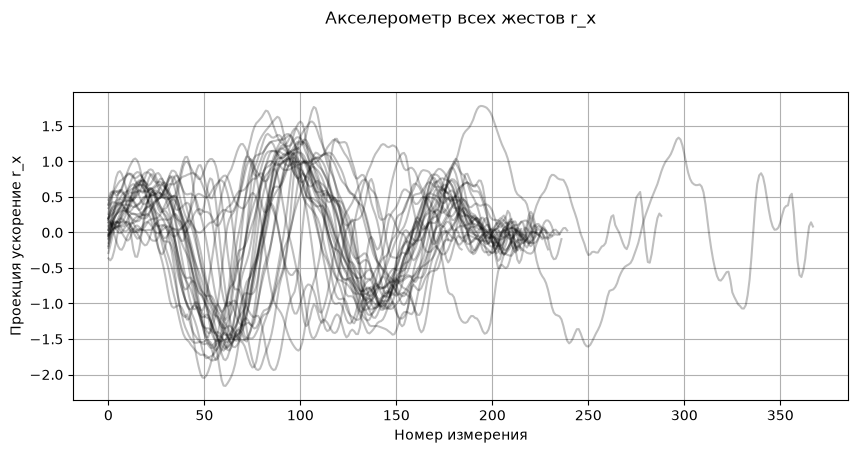

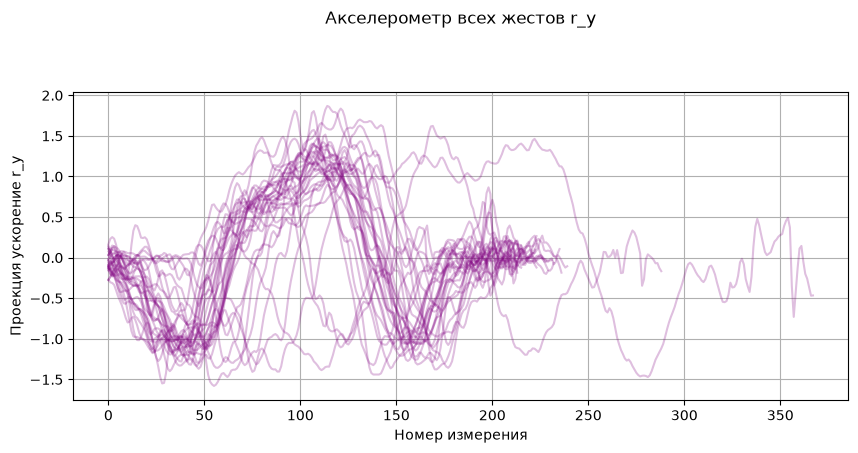

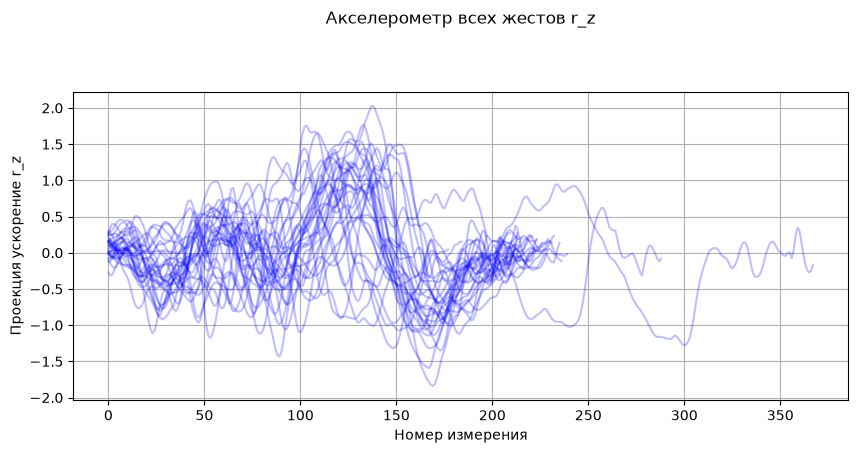

In [49]:
# функция приведения значений угла/угловой скорости r_x к общему типу
def prepare_rot_acc(time_series_matrix, amount_all_attributes, num_user):

    # ekashkarov, ochikin
    if num_user in {3, 9}:
        time_series_matrix[:, 0:3] /= 9.8
        time_series_matrix[:, 3:6] *= np.pi / 180

    # kovalexal, mfzaitseva, mkazachuk
    if num_user in {5, 6, 7}:
        time_series_matrix[:, 0:3] /= 9.8
        
        time_series_matrix[:, 3:6] = np.unwrap(
            time_series_matrix[:, 3:6],
            period=360,
            axis=0
        )
        
        time_series_matrix[:, 3:6] = np.deg2rad(time_series_matrix[:, 3:6])
        
        time_seconds = 0.02
        time_series_matrix[:, 3:6] = np.gradient(
            time_series_matrix[:, 3:6],
            time_seconds,
            axis=0
        )
    
    # вычитаем начальную ориентацию
    #for i in range(amount_all_attributes):
        #time_series_matrix[:, i] = time_series_matrix[:, i] - time_series_matrix[:, i][0]
    return time_series_matrix

# функция полной фильтрации жеста
def full_filt_gesture(user_folders, train_valid_test, 
                      num_user, num_file, amount_all_attributes, filt):
    
    # парсим атрибуты (временные ряды) из матрицы для i-ого файла
    time_series_matrix = get_gesture(user_folders, train_valid_test, num_user, num_file)

    # приводим углы и вычисляем относительные значени
    time_series_matrix = prepare_rot_acc(time_series_matrix, amount_all_attributes, num_user)
    
    # если фильтрация нужна
    if filt == 1: time_series_matrix = butterworth_filter_gesture(time_series_matrix)
    if filt == 2: time_series_matrix = median_filter_gesture(time_series_matrix)
    return time_series_matrix
    
# функция построения графика одной проекций (атрибута/временного ряда) для всех жестов
def build_one_attribute_plot(user_folders, train_valid_test, num_user, 
                             num_time_series, filt, amount_all_attributes):
    plt.figure(figsize=(10, 4))
    match num_time_series:
        case 0:
            attribute_name = "a_x"
            color_name = "yellow"
        case 1:
            attribute_name = "a_y"
            color_name = "red"
        case 2:
            attribute_name = "a_z"
            color_name = "green"
        case 3:
            attribute_name = "r_x"
            color_name = "black"
        case 4:
            attribute_name = "r_y"
            color_name = "purple"
        case 5:
            attribute_name = "r_z"
            color_name = "blue"

    # считаем кол-во жестов пользователя
    result_path = user_folders[num_user] / "inf" / train_valid_test
    gesture_len = len(list(result_path.iterdir())) - 1
    
    for i in range(gesture_len):
        # парсим и если фильтруем матрицу арибутов
        time_series_matrix = full_filt_gesture(user_folders, train_valid_test, 
                                              num_user, i, amount_all_attributes, filt)
        # отображаем атрибут на графике
        plt.plot(time_series_matrix[:, num_time_series], label=attribute_name, color=color_name, alpha=0.25)

    plt.title("Акселерометр всех жестов " + attribute_name + "\n\n\n")
    plt.xlabel("Номер измерения")
    plt.ylabel("Проекция ускорение " + attribute_name)
    plt.grid(True)
    
    plt.show()

# непосредственно строим все графики
amount_all_attributes = 6
for i in range(amount_all_attributes):
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=0, amount_all_attributes=6)


Применим реализованный фильтр Баттерворта ко всем этим рядам

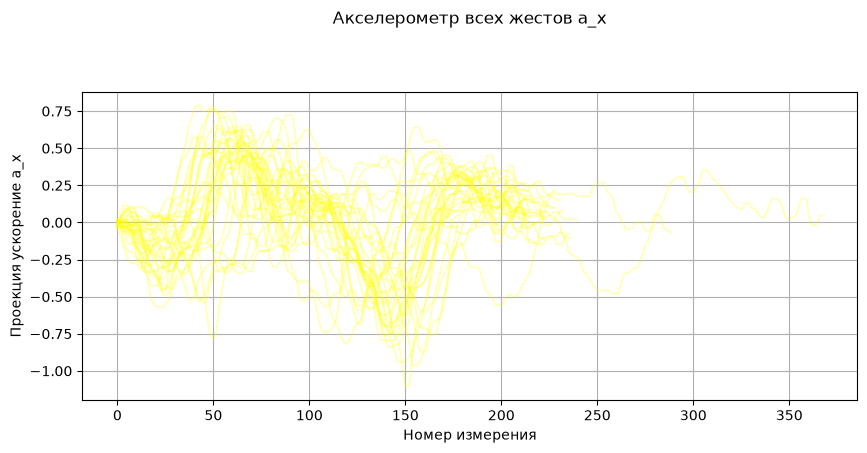

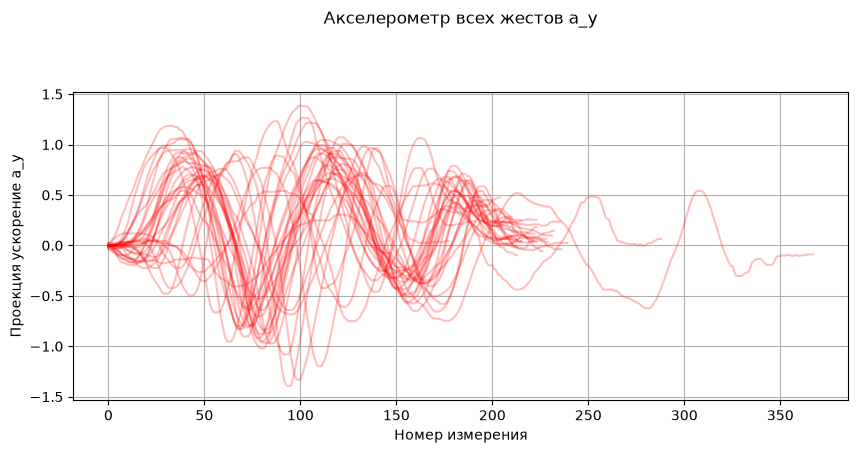

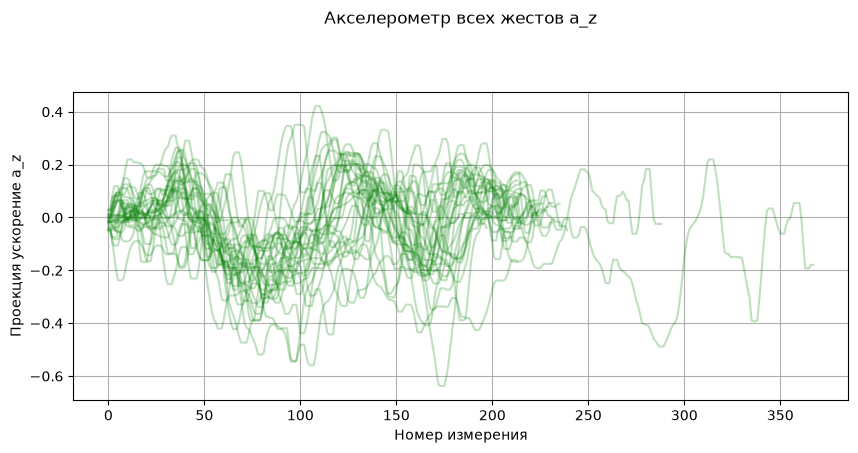

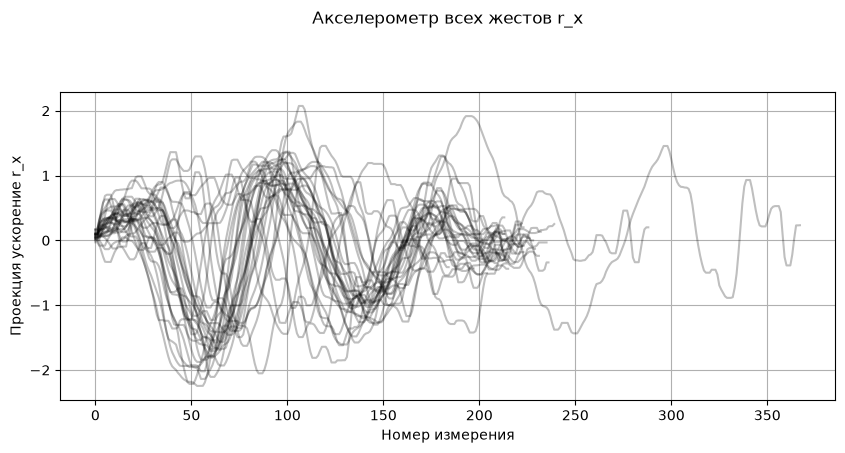

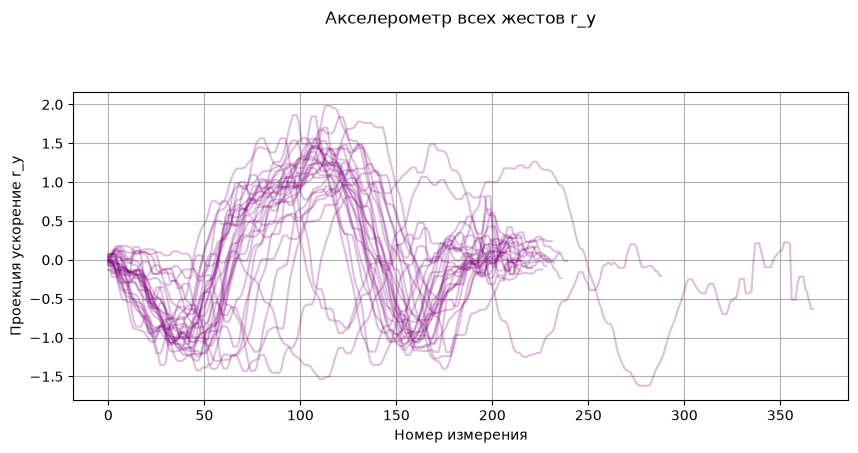

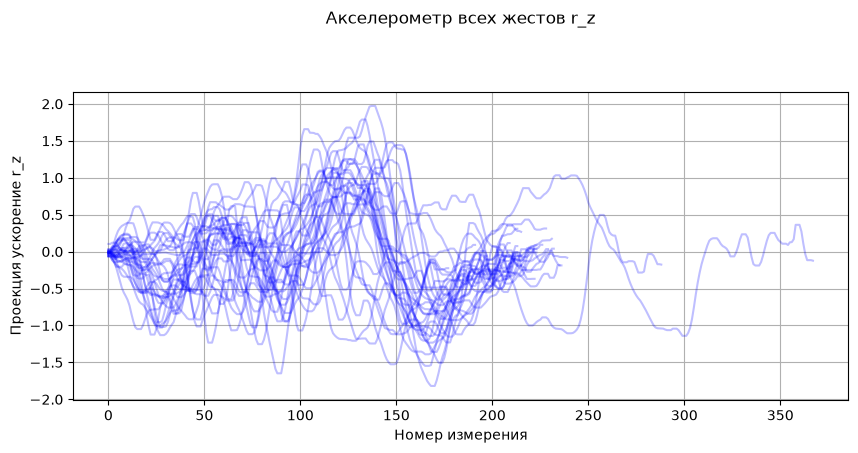

In [35]:
for i in range(amount_all_attributes):
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=2, amount_all_attributes=6)

Создаем таблицу для обучения модели: 30 жестов x 42 признака
42 признака = 6 временных рядов x 7 статистик
ститистика - среднее/медиана/мода/квантиль и д.р. Это то, что используется для описания примерного поведения ряда

In [52]:
def extract_features(processed_gesture):
    mean_values = np.mean(processed_gesture, axis=0)
    std_values = np.std(processed_gesture,axis=0)
    min_values = np.min(processed_gesture,axis=0)
    max_values = np.max(processed_gesture,axis=0)
    median_values = np.median(processed_gesture,axis=0)
    q1_values = np.percentile(processed_gesture, 25,axis=0)
    q3_values = np.percentile(processed_gesture, 75,axis=0)
    excess_values = kurtosis(processed_gesture, axis=0, bias=False)
    skewness_values = skew(processed_gesture, axis=0, bias=False)
    p87_values = np.percentile(processed_gesture, 87, axis=0)
    iqr_values = q3_values - q1_values
    sem_values = sem(processed_gesture, axis=0)
    
    features = np.concatenate([
        mean_values,
        std_values,
        min_values,
        max_values,
        median_values,
        q1_values,
        q3_values,
        excess_values,
        skewness_values,
        p87_values,
        iqr_values,
        sem_values
    ])

    return features


# функция получения всех векторов признаков для пользователя
def get_user_features(user_folders, train_valid_test, num_user, filt):
    # парсим все жесты пользователя
    result_path = user_folders[num_user] / "inf" / train_valid_test
    
    if len(list(result_path.glob("*.txt"))) > 0: 
        gesture_files = list(result_path.glob("*.txt"))
    else: 
        gesture_files = list(result_path.glob("*.json"))

    feature_rows = [] # матрица из строк = векторов признаков
    for i in range(len(gesture_files)):
        # подготавливаем углы и фильтруем
        filtered_gesture = full_filt_gesture(
            user_folders,
            train_valid_test,
            num_user=num_user,
            num_file=i,
            amount_all_attributes=6,
            filt=filt
        )
    
        # получаем 42 признака
        features = extract_features(filtered_gesture)
        feature_rows.append(features)
    return np.array(feature_rows, dtype=float)


# создаем имена признаков = (имя статистики) * (имя атрибута)
attribute_names = ["a_x", "a_y", "a_z", "r_x", "r_y", "r_z"]
statistic_names = ["mean", "std", "min", "max", "median", "q1", "q3", "excess", "skewness", "p87", "iqr", "sem"]
feature_names = []

for statistic_name in statistic_names:
    for attribute_name in attribute_names:
        feature_name = (statistic_name + "_" + attribute_name)
        feature_names.append(feature_name)

# получаем матрицу из векторов признаков по всем жестам: (30 жестов)*(42 признака)
feature_rows = []
feature_rows = get_user_features(user_folders, "train", num_user=0, filt=1)
X_train = feature_rows

# названия строк - имена файлов с жестами
gesture_file_names = []
result_path = user_folders[0] / "inf" / "train"
    
if len(list(result_path.glob("*.txt"))) > 0: 
    gesture_files = list(result_path.glob("*.txt"))
else: 
    gesture_files = list(result_path.glob("*.json"))

for i in range(len(gesture_files)):
    gesture_file_names.append(gesture_files[i].name)

# создаем красивую табличку с признаками по жестам
features_table = pd.DataFrame(feature_rows, index=gesture_file_names, columns=feature_names)
features_table.index.name = "gesture_file"

# показываем все признаки по первым 5-ти жестам
pd.set_option("display.max_columns", None)
display(features_table.head())

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,-0.053477,0.026188,-0.076375,0.030012,0.013004,0.010478,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.585463,-0.620304,-0.395637,-1.578372,-1.472751,-1.274473,0.359413,0.679530,0.318767,1.789530,1.405902,0.910753,-0.035000,-0.005829,-0.045658,0.142445,-0.021489,0.058521,-0.181787,-0.186972,-0.182904,-0.653433,-0.507015,-0.243535,0.063512,0.293952,0.033013,0.643442,0.524933,0.350672,-0.019536,-0.670093,-0.404576,-0.836590,-0.841933,0.577305,-0.378085,0.053901,-0.238719,-0.117591,0.062412,-0.642775,0.201444,0.422945,0.063650,0.995541,1.161593,0.497218,0.245299,0.480924,0.215917,1.296875,1.031948,0.594207,0.011080,0.016804,0.007662,0.044491,0.041872,0.024893
s_infinity_11_12_2022_0_17_38.json,-0.019213,0.019203,-0.051377,-0.029481,-0.011499,0.003877,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.564343,-0.815402,-0.364178,-1.478604,-1.405456,-1.026890,0.421629,0.562088,0.139642,1.243586,1.585805,0.845642,0.005004,-0.010627,-0.024570,0.034408,-0.063968,0.044612,-0.175314,-0.205793,-0.150317,-0.312900,-0.544671,-0.292670,0.161074,0.338032,0.043183,0.366025,0.594886,0.320512,-0.238982,-0.482214,-0.564457,-0.359247,-0.741244,-0.308865,-0.365987,-0.300001,-0.541365,-0.383341,0.188023,-0.333850,0.225041,0.468147,0.072239,0.766860,1.047399,0.546921,0.336388,0.543825,0.193499,0.678925,1.139557,0.613182,0.013546,0.020309,0.007181,0.040108,0.045828,0.027356
s_infinity_11_12_2022_0_19_18.json,-0.023291,0.021345,-0.050465,-0.027076,-0.047118,-0.012399,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.552503,-1.046405,-0.366320,-1.415651,-0.989576,-0.988329,0.585062,0.815931,0.321082,1.064495,1.479997,1.150964,0.014448,-0.040146,-0.043857,0.116555,-0.164784,-0.011538,-0.254705,-0.271919,-0.164630,-0.412124,-0.664285,-0.540445,0.182003,0.435135,0.038589,0.538294,0.267329,0.417505,-0.632223,-0.715144,0.031560,-0.814587,-0.380533,-1.003991,-0.103573,-0.173019,0.171721,-0.525533,0.764012,0.193550,0.252881,0.645903,0.074970,0.713774,0.910191,0.820870,0.436709,0.707054,0.203218,0.950419,0.931614,0.957950,0.021483,0.036115,0.010882,0.050492,0.052161,0.045675
s_infinity_11_12_2022_0_19_26.json,-0.021070,0.033198,-0.055340,-0.038744,-0.036439,-0.006328,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.823441,-1.013781,-0.322439,-1.131695,-1.090035,-0.894545,0.493704,0.911024,0.236750,1.220965,1.330286,1.314110,0.019899,0.005063,-0.046458,-0.006667,-0.107086,-0.063768,-0.241542,-0.302589,-0.190918,-0.584541,-0.639408,-0.467827,0.256612,0.456798,0.055620,0.506433,0.444701,0.283084,-0.301583,-0.715556,-1.029891,-1.020419,-0.881997,-0.457646,-0.633329,-0.235292,0.088590,-0.135659,0.332395,0.534686,0.334469,0.617374,0.104870,0.720308,1.004108,0.924484,0.498154,0.759387,0.246538,1.090973,1.084109,0.750911,0.024122,0.035897,0.010519,0.049041,0.051127,0.044289
s_infinity_11_12_2022_0_20_36.json,-0.039779,0.037564,-0.095024,-0.014994,0.000739,0.011968,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.046485,-1.462321,-0.539488,-1.957033,-1.343348,-0.957605,0.739486,0.977705,0.168822,1.547696,1.778205,1.382587,-0.004710,-0.008155,-0.057709,0.077371,-0.087160,0.017195,-0.253547,-0.358450,-0.195917,-0.603010,-0.661621,-0.501552,0.137979,0.516230,0.034051,0.635255,0.558280,0.35600

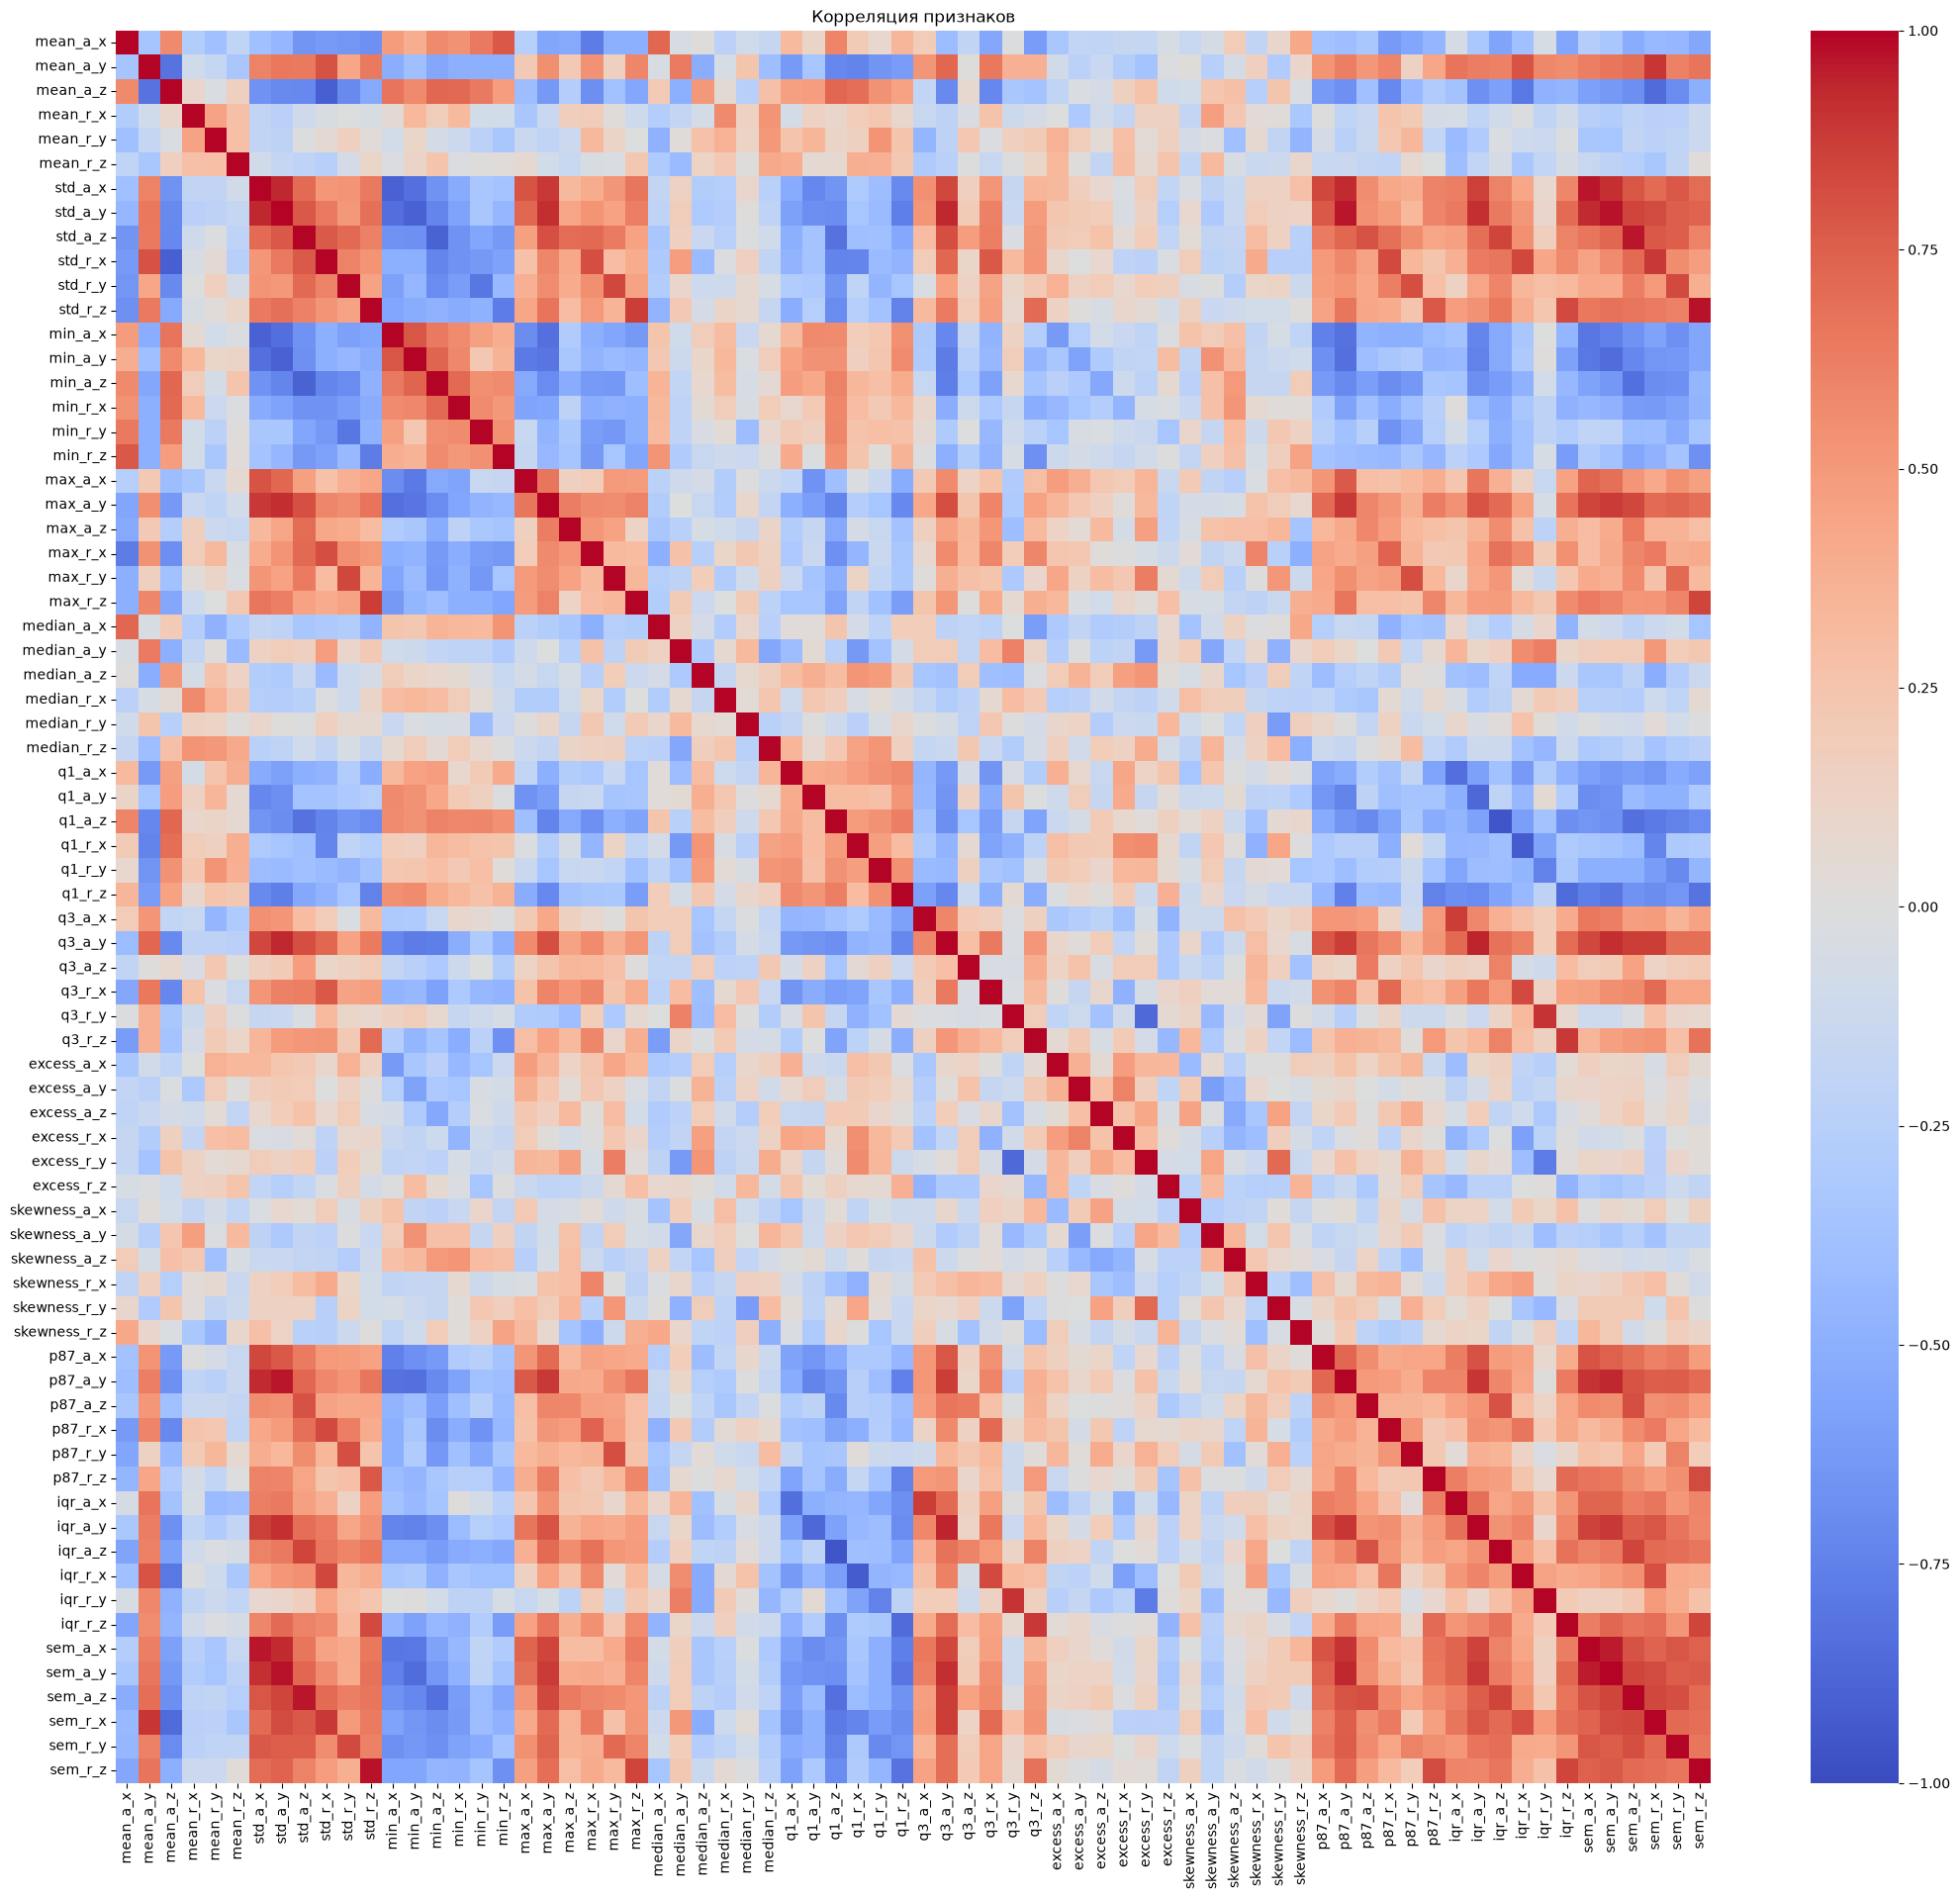

std_a_y   sem_a_y    0.975428
std_r_z   sem_r_z    0.974982
std_a_x   sem_a_x    0.967519
std_a_y   p87_a_y    0.963703
std_a_z   sem_a_z    0.961141
q1_a_z    iqr_a_z   -0.957138
sem_a_x   sem_a_y    0.956747
q3_a_y    iqr_a_y    0.942545
std_a_x   std_a_y    0.934636
p87_a_y   sem_a_y    0.934165
std_a_y   q3_a_y     0.930966
std_a_x   p87_a_y    0.928495
q1_r_x    iqr_r_x   -0.926410
std_a_y   sem_a_x    0.923201
          max_a_y    0.916899
q3_a_y    sem_a_y    0.914321
std_a_x   sem_a_y    0.913928
std_a_y   iqr_a_y    0.908542
mean_a_z  std_r_x   -0.907404
p87_a_y   sem_a_x    0.904719
dtype: float64

mean_a_x  mean_a_x         NaN
          mean_a_y    0.445302
          mean_a_z    0.320934
          mean_r_x   -0.532098
          mean_r_y    0.538338
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.445302,0.320934,-0.532098,0.538338,-0.245029,-0.141388,-0.512491,-0.485539,-0.534095,0.191385,-0.386928,0.140414,0.628987,0.392484,0.361629,0.477058,0.536869,0.041681,-0.549435,-0.515511,-0.710740,0.098390,0.007366,0.428033,0.705758,0.316566,-0.589858,0.109786,-0.147023,-0.164063,0.018042,0.382215,0.154856,-0.279446,-0.027073,0.412167,-0.307834,-0.175288,-0.099424,0.388975,-0.629698,0.020719,-0.435635,-0.352645,-0.087474,-0.563283,-0.196521,0.055186,-0.024510,0.086766,-0.553304,0.083127,0.400845,0.123792,-0.672639,-0.211384,-0.820389,0.206648,-0.244988,0.336432,-0.228774,-0.385092,-0.144033,0.514485,-0.600917,0.043686,-0.374923,-0.377565,-0.378592,0.312234,-0.277714
mean_a_y,0.445302,1.000000,-0.337144,-0.668169,0.177693,-0.206806,0.382064,0.191068,0.165213,0.261273,0.739729,0.304319,-0.211797,0.136646,-0.350226,-0.341975,0.004478,0.048313,0.070729,0.221914,-0.129547,-0.035632,0.392009,0.502420,0.583359,0.893061,-0.080435,0.201560,0.250702,-0.532314,-0.349613,-0.157993,0.020422,-0.618283,-0.693602,0.130145,0.615798,0.295200,-0.256131,0.347412,0.163286,-0.796096,0.144552,-0.349652,0.470085,-0.237418,-0.747747,0.318433,-0.315430,-0.337367,-0.578765,-0.403195,0.203846,0.490599,0.644722,-0.009096,-0.255340,-0.128467,0.793835,0.394059,0.568346,0.272806,-0.159237,0.549641,0.672471,-0.816970,0.527597,0.315121,0.280888,0.410663,0.802471,0.448560
mean_a_z,0.320934,-0.337144,1.000000,0.047674,-0.029780,-0.338976,-0.887446,-0.773599,-0.552353,-0.782542,-0.767019,-0.160906,0.775967,0.640755,0.592947,0.671968,0.579997,0.030553,-0.558069,-0.798396,-0.134512,-0.591435,-0.656607,-0.378700,-0.263227,-0.167244,0.741872,-0.397618,0.098340,0.026083,0.142603,0.720037,0.843692,0.837030,0.401067,-0.371499,-0.343487,-0.798364,0.129020,-0.783583,-0.217252,0.301034,-0.574807,-0.154266,-0.458187,0.321672,0.112037,-0.258546,0.543513,0.336488,0.367548,-0.221230,-0.150984,-0.278723,-0.654861,-0.665276,0.177987,-0.550633,-0.578368,-0.297854,-0.284068,-0.848959,-0.560123,-0.904868,-0.481414,0.421199,-0.782805,-0.754815,-0.566098,-0.778146,-0.668669,-0.217478
mean_r_x,-0.532098,-0.668169,0.047674,1.000000,-0.421153,0.113797,0.031702,0.310690,0.326906,0.090538,-0.330192,-0.331530,-0.099548,-0.451120,-0.058626,-0.079407,-0.136901,0.018012,0.322031,0.241498,0.464797,0.452156,-0.585967,-0.585209,-0.414770,-0.730969,-0.040326,0.080304,-0.249438,0.313871,0.339764,-0.101742,-0.215466,0.456135,0.374079,0.021469,-0.338007,0.106068,0.454403,0.045126,-0.058803,0.761504,0.114671,0.338222,-0.040966,0.410880,0.289063,-0.518746,0.101509,0.046176,0.187204,0.225205,-0.379250,-0.423210,-0.553510,0.531669,0.471144,0.353629,-0.448411,-0.190656,-0.404928,0.115099,0.416898,-0.250802,-0.340631,0.730625,-0.045751,0.234846,0.263850,0.022397,-0.325268,-0.367939
mean_r_y,0.538338,0.177693,-0.029780,-0.421153,1.000000,-0.184622,0.151787,-0.304871,-0.463758,-0.281455,0.273025,-0.313247,-0.134925,0.371814,0.408523,0.348800,0.078919,0.261894,-0.169657,-0.384528,-0.519531,-0.586950,0.385508,-0.062160,0.594421,0.483032,0.273909,-0.477375,0.364840,-0.320550,0.034772,-0.247663,0.023977,-0.135349,0.244623,-0.109245,0.125763,-0.065404,-0.229364,0.134977,0.681205,-0.550906,0.091169,-0.410265,-0.526219,-0.425105,-0.317284,-0.052274,-0.260990,-0.030747,0.309960,-0.182050,-0.094323,0.317025,0.288334,-0.482945,-0.511708,-0.354882,0.371638,0.081172,0.049317

mean_a_x  mean_a_x         NaN
          mean_a_y    0.031618
          mean_a_z    0.366658
          mean_r_x    0.008706
          mean_r_y    0.205017
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.031618,0.366658,0.008706,0.205017,0.255506,0.040541,-0.453326,-0.097871,-0.362988,-0.143248,-0.441355,0.213324,0.390885,0.106109,0.466237,0.242546,0.039653,0.375549,-0.105971,-0.239443,-0.263663,-0.036128,-0.830127,0.153980,-0.172733,-0.074728,-0.181470,-0.067048,0.543123,0.144013,0.591107,0.230123,0.110627,0.105675,0.304153,0.490106,-0.746489,0.312600,-0.096971,0.148334,-0.182984,0.262190,0.149851,0.178306,0.016127,0.127351,0.078699,0.164163,0.457967,-0.203459,0.323076,0.025447,-0.552270,-0.174703,-0.023078,0.042897,-0.090421,0.257746,-0.198393,0.252874,-0.696608,-0.047951,-0.111015,0.000612,-0.269566,0.069221,-0.367935,-0.060461,-0.286076,-0.028053,-0.351405
mean_a_y,0.031618,1.000000,-0.737180,-0.053389,0.161364,-0.681397,0.778343,0.674402,0.813320,0.766124,0.191251,0.831868,-0.272607,0.096573,-0.597066,-0.319566,0.253392,-0.848153,0.587965,0.633990,0.621884,0.732805,0.342314,0.117654,-0.394858,0.563725,-0.201382,-0.058210,0.015509,-0.326630,-0.673135,-0.656182,-0.609290,-0.330457,-0.461799,-0.406320,0.597457,0.496008,0.473294,0.454237,0.059992,0.250455,-0.291733,-0.214798,-0.341626,0.040346,-0.372067,-0.030864,0.175422,0.597444,0.280290,-0.179571,0.514441,-0.324835,0.569685,0.858176,0.630649,0.730854,0.175025,0.872351,0.758678,0.568129,0.693145,0.426623,0.327509,0.363131,0.796646,0.741880,0.825742,0.830642,0.438323,0.880338
mean_a_z,0.366658,-0.737180,1.000000,0.204328,-0.165828,0.499984,-0.611506,-0.786673,-0.573441,-0.745422,-0.579403,-0.821791,0.592054,0.229231,0.435749,0.669225,0.055595,0.567914,-0.282249,-0.730636,-0.344378,-0.576505,-0.357139,-0.608213,0.433575,-0.302329,0.158497,-0.105644,-0.230632,0.292927,0.312205,0.773331,0.789154,0.099202,0.668407,0.105769,-0.093309,-0.693970,-0.021966,-0.142733,-0.350391,-0.238253,0.166775,-0.000078,0.488338,-0.392085,0.357461,-0.251854,0.189951,-0.402104,-0.408234,0.432086,-0.155549,-0.035718,-0.573084,-0.604142,-0.231936,-0.489734,-0.256164,-0.585328,-0.228387,-0.737035,-0.640536,-0.131749,-0.596913,-0.181452,-0.607243,-0.788823,-0.570406,-0.752241,-0.650075,-0.815885
mean_r_x,0.008706,-0.053389,0.204328,1.000000,-0.604484,-0.059945,-0.197478,-0.010520,-0.064910,0.214504,-0.399703,-0.115458,0.341081,-0.102622,0.162714,0.165207,0.218802,0.095273,-0.060217,-0.153800,-0.086387,0.003051,-0.268277,0.104637,-0.138783,0.340895,-0.275023,0.834659,-0.741211,-0.079673,-0.212458,-0.002911,0.246735,-0.083332,0.121306,-0.264374,0.135059,-0.196545,0.045768,0.602646,0.099341,-0.000249,-0.299924,-0.085859,-0.142066,-0.643718,-0.145394,-0.138834,0.074965,-0.426441,0.117596,-0.454853,0.310803,0.141230,-0.062910,0.075333,0.220595,0.229579,-0.271453,0.042892,0.203502,-0.120056,-0.177361,0.389359,-0.032369,0.154294,-0.207040,-0.050908,-0.086324,0.152468,-0.441271,-0.143626
mean_r_y,0.205017,0.161364,-0.165828,-0.604484,1.000000,0.069139,-0.162504,-0.272476,-0.238895,-0.245708,0.036430,0.065656,0.081372,0.658076,0.319577,0.331798,0.316348,-0.297701,0.022761,-0.159964,0.320401,0.093522,-0.000534,-0.329891,0.175423,-0.109880,-0.429454,-0.622780,0.817478,0.575109,0.389946,-0.169961,-0.332304,0.163368,-0.473890,-0.056738,0.162660,0.160188,-0.202331,-0.282143,0.469751,0.563522,0.438291,-0.431032,-0.240372,0.285508,-0.464653,-0.158013,-0.166500,0.548864,0.364807,0.522331,-0.032663,-0.727963,-0.420986,-0.031163,-0.120014,-0.427190,-0.057842,-0.185892,-0.097659

mean_a_x  mean_a_x         NaN
          mean_a_y    0.418800
          mean_a_z   -0.061503
          mean_r_x   -0.150052
          mean_r_y   -0.371482
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.418800,-0.061503,-0.150052,-0.371482,-0.047260,0.285432,0.432291,-0.108345,0.450704,-0.191087,0.477183,-0.483480,-0.590649,-0.101159,-0.558242,-0.021931,-0.565143,0.252127,0.335449,-0.241144,0.090350,-0.645671,0.540674,0.803534,0.536593,-0.002236,0.023484,-0.396243,-0.249868,0.114910,-0.485076,-0.027301,0.032684,0.097969,-0.048139,0.343682,0.602205,-0.226868,0.141378,-0.143873,0.196849,0.316839,-0.123728,-0.009700,0.109913,-0.332195,0.387706,-0.210312,-0.197829,-0.125233,-0.249512,-0.301587,-0.162929,0.141796,0.178877,-0.026087,0.156764,0.073113,0.378730,0.041692,0.565479,-0.077404,0.070938,-0.140767,0.141570,0.411597,0.491898,0.072388,0.519721,0.050423,0.536961
mean_a_y,0.418800,1.000000,-0.508907,-0.204139,-0.130491,-0.573077,0.690819,0.848959,0.295830,0.783908,0.376846,0.609857,0.059288,-0.706708,-0.469767,-0.558416,-0.350837,-0.356683,0.817334,0.586050,0.096020,-0.208894,-0.238244,0.284349,0.007809,0.387735,-0.285238,0.050825,-0.426923,-0.606293,-0.402128,-0.770935,-0.319617,-0.206463,-0.180998,-0.543340,0.539812,0.719021,-0.464216,0.695078,0.432825,-0.053701,0.106606,-0.302005,0.445723,-0.596458,-0.406081,-0.224893,0.467342,-0.102795,-0.147272,-0.335048,-0.346383,-0.019475,0.426243,0.765888,-0.105131,0.509075,0.600085,0.563679,0.520232,0.753680,0.058306,0.581008,0.374679,0.366094,0.784379,0.859452,0.472313,0.834274,0.622500,0.723024
mean_a_z,-0.061503,-0.508907,1.000000,-0.022103,0.108337,0.271889,-0.713591,-0.549504,-0.552373,-0.647546,-0.780738,-0.501005,-0.268479,0.144851,0.647217,0.198051,0.394612,0.340757,-0.721893,-0.641472,-0.041001,-0.304493,-0.332301,-0.073290,0.171818,-0.345821,0.784985,-0.076038,0.695757,0.031127,0.757917,0.474993,0.784059,0.772229,0.394785,0.258066,-0.566473,-0.424501,0.317917,-0.613627,-0.225826,-0.233998,-0.104734,0.572621,-0.172122,0.514447,-0.121859,0.251174,-0.634607,-0.369775,0.192535,-0.283444,-0.381221,0.362362,-0.314804,-0.540251,-0.081967,-0.354459,-0.897387,-0.314088,-0.808129,-0.453087,-0.504250,-0.886110,-0.324374,-0.314357,-0.618393,-0.476352,-0.530552,-0.542007,-0.770802,-0.481299
mean_r_x,-0.150052,-0.204139,-0.022103,1.000000,0.106026,0.157631,-0.143783,-0.141547,0.154776,0.089224,-0.254404,-0.275989,-0.324330,0.148747,-0.141870,0.164929,0.296217,0.337096,0.025009,-0.063492,0.039485,0.395527,0.056926,0.072371,-0.267057,0.091832,0.100992,-0.092977,-0.292242,-0.299496,0.043561,0.055830,-0.186487,0.324626,0.287007,-0.070476,0.037726,0.003915,0.198069,0.298370,-0.579836,0.069732,0.523380,-0.212253,-0.070767,-0.065989,0.165680,0.221599,-0.071269,0.111375,0.015019,0.410116,0.630841,0.343946,0.111386,-0.160590,0.272299,0.578191,-0.272542,-0.090226,-0.019579,-0.020472,0.240370,-0.012003,-0.521049,0.089004,-0.175489,-0.157174,0.079013,-0.008467,-0.317278,-0.288595
mean_r_y,-0.371482,-0.130491,0.108337,0.106026,1.000000,-0.080482,0.307568,0.160603,0.683835,0.208996,0.192485,0.248948,-0.417581,0.063241,-0.370457,-0.169244,-0.186469,-0.348605,0.013856,0.194250,0.638576,0.554612,0.622391,-0.315656,-0.250582,-0.794846,0.088131,0.006042,0.500458,0.146510,0.060457,-0.141391,-0.362200,0.144606,0.368076,-0.325000,0.509568,-0.004469,0.725870,0.266442,0.312922,0.611514,-0.217566,-0.253588,0.035461,0.487871,0.567381,-0.665576,-0.258320,0.487105,0.186147,0.026498,0.171746,-0.372745,0.552689,0.364082,0.693517,0.162165,0.109568,0.390657,0.147609,0.055163,0

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.558132
          mean_a_z    0.569469
          mean_r_x   -0.112625
          mean_r_y    0.033565
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.558132,0.569469,-0.112625,0.033565,0.079714,-0.599491,-0.692323,-0.505405,-0.498574,-0.484425,-0.671747,0.550380,0.587554,0.182305,0.623672,-0.018669,0.524434,-0.659378,-0.701035,-0.470985,-0.397001,-0.465930,-0.819378,0.302379,-0.395755,-0.174860,-0.018567,0.037069,0.032254,0.449086,0.132897,0.556227,0.166316,0.692525,0.537729,0.215597,-0.338296,-0.034853,-0.163739,-0.245508,-0.036948,-0.160368,0.011270,0.421501,-0.230918,0.476587,-0.261449,-0.629902,0.424589,-0.311114,-0.085698,-0.211871,-0.376132,-0.038034,-0.715993,-0.045222,-0.478300,-0.661783,-0.385547,-0.196243,-0.250771,-0.439462,-0.186836,-0.504901,-0.339278,-0.563119,-0.635775,-0.515167,-0.510202,-0.489195,-0.730071
mean_a_y,-0.558132,1.000000,-0.803133,0.490958,-0.616423,0.168843,0.867350,0.665198,0.953167,0.872006,0.775803,0.703277,-0.819837,-0.554756,-0.782906,-0.697770,-0.427719,-0.273298,0.596860,0.352747,0.381090,0.708761,0.333383,0.717826,0.524939,0.840939,-0.035650,0.552653,0.018768,-0.386823,-0.823666,-0.479801,-0.667568,-0.367502,-0.844299,-0.601124,0.392673,0.756486,0.627701,0.730986,0.632439,0.462080,-0.343461,-0.398483,-0.230886,-0.080277,-0.194073,0.104886,0.172018,-0.661812,-0.004847,-0.479816,-0.270501,0.598401,0.651519,0.689434,0.643445,0.775587,0.536326,0.385046,0.701703,0.651087,0.727498,0.621656,0.787405,0.577985,0.855543,0.717890,0.960379,0.891218,0.805279,0.865280
mean_a_z,0.569469,-0.803133,1.000000,-0.598741,0.596549,-0.033102,-0.954447,-0.880914,-0.795860,-0.935107,-0.970202,-0.522701,0.877167,0.690886,0.486261,0.708741,0.585319,0.243719,-0.776629,-0.526508,-0.011748,-0.737020,-0.651045,-0.498563,-0.396460,-0.539502,0.342271,-0.406184,0.302691,0.203824,0.616676,0.557612,0.749170,0.071982,0.955463,0.528761,-0.210084,-0.852911,-0.365770,-0.682911,-0.798204,-0.377960,0.204031,0.432698,0.509963,0.035799,0.034972,0.097238,-0.392440,0.710345,-0.210938,0.516747,0.167553,-0.284826,-0.580691,-0.864333,-0.392953,-0.878690,-0.866001,-0.429288,-0.488973,-0.742314,-0.700777,-0.427043,-0.933634,-0.494951,-0.928815,-0.885188,-0.848103,-0.957018,-0.973070,-0.727709
mean_r_x,-0.112625,0.490958,-0.598741,1.000000,-0.306189,-0.323325,0.702224,0.669431,0.516719,0.518664,0.585294,-0.148669,-0.672578,-0.526083,-0.329558,-0.169671,-0.395238,0.450552,0.520676,0.055223,-0.168226,0.514477,0.578402,0.152906,0.686457,0.691194,0.134390,0.790772,-0.737079,-0.486486,-0.702612,-0.792412,-0.549903,0.219113,-0.597465,-0.095866,0.646492,0.729728,0.398966,0.391749,0.562866,-0.052495,-0.329928,-0.466764,-0.293827,-0.086459,0.002025,0.250988,0.123416,-0.631711,0.083250,-0.197503,0.115828,0.388696,0.484911,0.631226,0.235734,0.756118,0.469520,-0.369869,0.733675,0.791062,0.558940,0.097445,0.616696,0.032585,0.767976,0.754871,0.657855,0.686791,0.692321,0.139714
mean_r_y,0.033565,-0.616423,0.596549,-0.306189,1.000000,-0.634386,-0.594646,-0.345076,-0.600609,-0.720616,-0.672164,-0.479533,0.686418,0.225831,0.604040,0.526802,0.825605,0.262236,-0.530782,-0.426405,-0.073128,-0.749181,0.070793,-0.317755,-0.608472,-0.354211,0.232633,-0.215578,-0.178617,0.122195,0.275087,0.116554,0.421376,0.159302,0.454767,0.121013,-0.105604,-0.428812,-0.259456,-0.688352,-0.474192,-0.339916,-0.072600,0.170397,-0.031003,-0.038458,-0.569020,0.066851,-0.039266,0.058864,0.185445,0.529978,0.784453,-0.225992,-0.584153,-0.414669,-0.450306,-0.544847,-0.231246,-0.467057,-0.2

mean_a_x  mean_a_x         NaN
          mean_a_y    0.168821
          mean_a_z   -0.555402
          mean_r_x    0.163154
          mean_r_y   -0.301838
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.168821,-0.555402,0.163154,-0.301838,0.238152,0.391004,0.537118,0.159778,0.193835,0.359214,0.221110,0.066983,-0.414971,-0.264727,-0.118093,0.059859,-0.280615,0.532701,0.730933,-0.207922,0.138929,-0.363406,-0.050107,0.539431,0.354826,0.162292,0.168856,0.341822,-0.124381,-0.401632,-0.338244,-0.670144,-0.236763,-0.308543,0.088458,0.490671,-0.496438,0.112676,0.231491,0.534670,0.205015,0.138701,0.583185,-0.275853,-0.006627,-0.532991,-0.065565,0.226089,0.358138,-0.091953,-0.147165,-0.524144,-0.607504,0.108853,0.300273,-0.113222,0.103454,0.394501,0.089773,0.579421,-0.137001,0.540260,0.329892,0.575573,0.115478,0.432539,0.582784,0.232109,0.309821,0.437966,0.287834
mean_a_y,0.168821,1.000000,-0.495475,0.532364,-0.130699,-0.155162,0.802506,0.692935,0.530744,0.409520,0.239237,0.931903,-0.445606,-0.628937,-0.258410,-0.360848,-0.443795,-0.686046,0.302477,0.659808,0.085138,-0.059621,0.260788,0.789320,0.369462,0.101127,0.197062,-0.025116,0.359393,0.157660,0.190078,0.329054,-0.224314,-0.039062,0.053672,-0.635655,0.362125,-0.069307,0.047330,0.363134,-0.425688,-0.321663,0.067001,0.748270,0.016646,0.046931,0.540297,0.293065,-0.373777,0.292509,-0.327049,-0.601786,0.365848,0.126861,0.693033,0.721496,0.263101,0.349258,0.295539,0.884655,0.042469,-0.217652,0.184347,0.319556,-0.367665,0.126200,0.743639,0.675885,0.596837,0.469451,0.298642,0.887519
mean_a_z,-0.555402,-0.495475,1.000000,-0.526055,0.328361,-0.028825,-0.749256,-0.640209,-0.376684,-0.138271,-0.749421,-0.557450,0.117146,0.250602,0.416442,0.351174,0.460689,0.465212,-0.696631,-0.839924,0.020850,-0.283840,-0.187986,-0.340711,-0.515593,-0.074506,0.154622,-0.569253,-0.273265,-0.176061,0.170853,-0.013535,0.683357,0.140355,0.641830,0.395595,-0.636367,0.344381,-0.078770,0.131073,-0.206670,-0.148969,-0.278177,-0.573463,-0.059809,-0.176912,0.027149,-0.025779,-0.084682,-0.537781,0.239578,0.280394,0.065662,0.461708,-0.050010,-0.328966,0.230307,-0.110195,-0.726490,-0.412996,-0.474345,0.225977,-0.537731,0.023352,-0.469060,-0.368405,-0.717525,-0.654612,-0.450674,-0.230396,-0.769995,-0.575040
mean_r_x,0.163154,0.532364,-0.526055,1.000000,-0.218916,0.304238,0.480661,0.561280,0.594751,0.186433,0.491679,0.343109,-0.823328,-0.526924,-0.523716,-0.315047,-0.375639,-0.682987,0.434799,0.515894,0.093467,0.059795,0.378246,0.635710,0.404555,0.059989,0.091577,-0.018026,0.702932,0.742890,0.156069,0.235584,-0.491902,0.199383,-0.592582,-0.187002,0.250059,-0.258241,0.422039,0.557173,-0.362792,-0.415900,0.737490,0.529836,0.323448,-0.095954,0.194705,0.698927,-0.349376,0.252225,-0.378925,-0.193096,-0.039015,-0.042211,-0.053340,0.399668,0.344050,-0.099062,0.520511,0.289089,0.009681,-0.288394,0.520370,0.335862,-0.012142,-0.229591,0.297090,0.368642,0.563867,0.057529,0.338449,0.210199
mean_r_y,-0.301838,-0.130699,0.328361,-0.218916,1.000000,-0.401144,-0.247255,-0.408282,0.306655,-0.043301,-0.086484,-0.135551,0.294474,0.169458,-0.241581,-0.613081,0.186079,0.119985,-0.161480,-0.317065,0.409600,0.392531,0.571881,-0.037215,-0.714024,-0.070608,0.072399,-0.127764,0.095294,-0.305967,-0.384008,0.248532,0.216855,0.681490,0.370246,0.366715,-0.418560,0.194793,0.457356,-0.193448,-0.133731,-0.426780,-0.218391,-0.277967,0.156789,0.802790,0.427891,0.293340,0.290907,-0.652430,0.099769,-0.374373,0.384109,0.631934,0.106806,-0.366134,0.504367,-0.302179,-0.379678,0.010689,0.080994,-0.007346,0.005344,-0.5637

mean_a_x  mean_a_x         NaN
          mean_a_y    0.468469
          mean_a_z   -0.538409
          mean_r_x   -0.460801
          mean_r_y   -0.163585
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.468469,-0.538409,-0.460801,-0.163585,0.305777,-0.385753,-0.567656,-0.040811,-0.016023,0.078657,-0.567478,0.715200,0.500559,-0.256695,0.407921,0.028387,0.599703,0.433720,0.033965,-0.404405,-0.599106,0.365940,-0.327681,0.978553,0.527613,-0.277776,0.342096,-0.138603,-0.071203,0.825463,0.555156,-0.406720,-0.441479,0.005563,0.675410,0.941718,0.300279,-0.652161,-0.111648,-0.341112,-0.019438,-0.163309,0.219591,0.022350,-0.741996,0.179051,-0.415160,-0.011126,-0.238124,-0.071547,-0.629203,0.160080,0.438314,0.838156,0.122594,-0.595996,0.568285,-0.101360,-0.496335,-0.154872,-0.554632,-0.173204,0.314755,-0.227180,-0.486720,-0.333077,-0.531574,-0.034909,-0.011979,0.081103,-0.564668
mean_a_y,0.468469,1.000000,-0.928230,-0.548310,-0.181289,0.442484,-0.313022,-0.635081,0.046951,0.434043,0.170052,-0.522874,0.775289,0.917333,-0.519957,0.037534,-0.184513,0.488588,0.150805,0.593525,0.191212,-0.016492,0.022500,-0.319272,0.531770,0.988791,-0.767182,0.126953,-0.045637,0.425686,0.048804,0.970563,-0.704811,-0.867066,-0.244392,0.240357,0.481629,0.874962,-0.854718,-0.053748,-0.347420,-0.112660,-0.679065,0.349014,0.328280,-0.424369,0.129868,-0.408937,0.519877,0.094861,0.019770,-0.119837,-0.227066,0.197763,0.402676,0.757877,-0.792970,0.744238,0.009821,-0.314876,0.426414,-0.606616,-0.056309,0.764722,-0.072568,-0.244508,-0.343390,-0.631561,-0.006633,0.327553,0.098540,-0.557372
mean_a_z,-0.538409,-0.928230,1.000000,0.557281,0.189924,-0.382677,0.232330,0.671935,-0.183915,-0.424429,-0.148601,0.620969,-0.743841,-0.916194,0.598669,-0.128412,0.112265,-0.531932,-0.368984,-0.483593,-0.279842,0.178105,-0.152940,0.235120,-0.598925,-0.913205,0.879430,-0.029694,-0.153101,-0.332597,-0.162761,-0.932679,0.866610,0.745908,0.148671,-0.212207,-0.549700,-0.744502,0.800997,-0.097436,0.338814,0.105916,0.554602,-0.307260,-0.227894,0.553431,-0.144523,0.301303,-0.488682,-0.195563,-0.184667,0.233808,0.148172,-0.324630,-0.434723,-0.671794,0.782360,-0.824490,0.266758,0.518680,-0.341699,0.682832,-0.152038,-0.785059,0.127719,0.220222,0.270064,0.663727,-0.121063,-0.324020,-0.084851,0.653696
mean_r_x,-0.460801,-0.548310,0.557281,1.000000,0.316263,-0.173925,0.532231,0.860173,0.478103,0.087420,0.298841,0.178301,-0.598729,-0.776148,-0.136644,0.144755,-0.062358,0.019283,0.035352,0.146150,0.060232,0.426956,0.353384,0.118165,-0.465515,-0.569402,0.623123,0.129785,0.366782,-0.121372,-0.351002,-0.648841,0.408099,0.668286,0.262312,-0.537718,-0.460962,-0.408596,0.674888,0.103609,0.091077,-0.337193,0.248583,0.044475,0.027410,0.502874,0.282049,-0.226759,-0.147557,-0.135509,-0.290244,0.393014,0.170040,0.192317,-0.272715,-0.027627,0.667176,-0.341179,0.188258,0.307274,0.003961,0.588437,0.191954,-0.534354,-0.106881,0.149697,0.589502,0.867959,0.521348,0.212900,0.431694,0.251118
mean_r_y,-0.163585,-0.181289,0.189924,0.316263,1.000000,0.610342,0.536621,0.437259,0.651702,0.515907,-0.582018,-0.013342,-0.396664,-0.301359,0.018398,-0.328297,0.800271,0.278006,0.468851,0.419969,0.532357,0.651317,0.369624,0.648372,-0.093403,-0.209396,0.190673,-0.006346,0.386955,0.422820,-0.191762,-0.288824,-0.097324,-0.073969,0.669697,-0.011209,0.037360,0.035364,0.513705,-0.642204,0.450721,0.209022,-0.030952,0.182969,-0.597045,0.687538,-0.610190,-0.291116,0.225028,0.389968,0.487008,0.711649,0.834242,0.451693,0.008195,-0.042115,0.632603,-0.381518,0.126353,0.177018,0.297891,0.487275,0.551

mean_a_x  mean_a_x         NaN
          mean_a_y    0.219505
          mean_a_z    0.151440
          mean_r_x    0.318089
          mean_r_y   -0.039527
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.219505,0.151440,0.318089,-0.039527,-0.142429,0.018236,-0.114040,0.259151,-0.109011,0.149983,0.257801,0.628325,0.347192,-0.077069,0.017864,-0.200370,0.127999,0.795618,0.111566,0.246955,-0.314944,-0.180772,0.163391,0.711129,0.283984,0.148872,-0.002396,0.358547,-0.488039,0.813566,0.110885,-0.138981,-0.042718,0.285382,-0.450013,0.873695,0.297444,0.075138,0.774372,-0.082522,0.319527,0.149542,-0.227188,-0.122641,-0.210315,-0.140146,-0.653541,0.634246,-0.139819,0.040650,-0.191015,-0.404568,0.542034,0.555149,0.123222,0.352154,0.043037,0.014295,0.712112,-0.063211,0.458822,0.133628,0.317616,-0.316034,0.509942,-0.257657,-0.358392,-0.040879,-0.359205,-0.156643,-0.051000
mean_a_y,0.219505,1.000000,-0.876295,-0.001032,0.696460,-0.057033,-0.143620,-0.110275,-0.436755,0.032135,-0.246923,0.591243,-0.252124,0.623530,0.035072,0.434828,-0.219598,-0.228583,-0.080319,0.634387,-0.687455,0.497016,-0.455839,0.462721,0.398267,0.977486,-0.715699,-0.351116,0.460427,-0.352928,0.193838,0.974852,-0.444992,-0.171464,0.386180,-0.453716,0.316926,0.935217,-0.675031,0.037603,0.338330,0.653547,0.231142,-0.458952,-0.077200,0.193022,-0.035565,-0.385228,-0.280564,-0.652550,0.138044,0.582934,-0.394651,0.124685,-0.119517,0.893908,-0.663074,-0.089155,0.003525,0.593201,0.094434,0.203327,-0.218069,0.152518,-0.133944,0.722550,-0.138877,-0.102015,-0.418260,0.011749,-0.234912,0.533587
mean_a_z,0.151440,-0.876295,1.000000,-0.002000,-0.809669,-0.059537,-0.067766,-0.108407,0.354386,-0.203402,0.193415,-0.639804,0.641907,-0.359048,0.183618,-0.235046,0.204767,0.491644,0.288262,-0.720566,0.797198,-0.664050,0.299958,-0.344346,-0.098441,-0.786585,0.778623,0.225919,-0.378521,0.058734,0.029192,-0.900802,0.456171,0.094020,-0.363709,0.217606,0.085663,-0.845512,0.648093,0.252124,-0.360314,-0.725905,-0.261384,0.347689,-0.111124,-0.389963,-0.055317,-0.016121,0.527653,0.629291,0.046202,-0.643312,0.275879,0.284779,0.215588,-0.900051,0.661637,-0.084216,-0.014831,-0.456080,0.052411,-0.145318,0.192581,0.016059,0.098952,-0.605935,-0.110554,-0.133766,0.283471,-0.213262,0.128755,-0.644754
mean_r_x,0.318089,-0.001032,-0.002000,1.000000,0.124622,0.008757,0.092386,0.106123,0.220806,-0.148459,0.246257,0.068995,0.150392,0.046718,-0.420028,-0.191858,0.082043,0.202876,0.510071,0.485002,0.328884,-0.351915,0.224454,0.235072,-0.182459,-0.037916,0.102384,0.438403,-0.105802,-0.359635,0.506750,0.002139,0.455624,0.568106,-0.067478,-0.234612,0.195583,0.025475,-0.441665,0.378608,-0.533811,0.109660,0.621361,0.599966,0.678994,0.170209,0.255071,-0.301665,0.425785,0.493563,-0.367759,-0.528839,0.198858,0.287305,0.069230,-0.168342,0.044510,0.001699,0.262960,0.239251,-0.390341,0.053858,-0.575878,-0.321408,-0.286428,0.230056,-0.156278,-0.141460,-0.044490,-0.348285,-0.037305,-0.181248
mean_r_y,-0.039527,0.696460,-0.809669,0.124622,1.000000,-0.152280,-0.075012,0.048994,-0.276021,-0.060327,-0.218412,0.568717,-0.436697,0.285626,-0.225723,0.235825,0.176688,-0.462841,-0.043752,0.631628,-0.373832,0.267075,-0.287073,0.389110,0.024055,0.624024,-0.844041,-0.237805,0.392148,-0.072007,0.303752,0.762643,-0.271656,0.263266,0.439895,-0.410682,-0.178454,0.694780,-0.656635,-0.336400,0.338851,0.586893,0.622018,-0.143682,0.265081,0.374252,-0.229842,-0.030556,-0.231005,-0.469628,0.094488,0.276366,-0.105057,-0.043244,-0.344390,0.696208,-0.595179,-0.111742,0.080142,0.519787,-0.531657,0.075023,-0.30

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.147353
          mean_a_z   -0.446372
          mean_r_x    0.581779
          mean_r_y    0.692742
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.147353,-0.446372,0.581779,0.692742,0.423457,-0.731750,-0.404299,-0.230678,-0.154275,-0.386830,0.325588,0.753666,0.202591,-0.041908,0.481047,0.577886,-0.170174,0.664057,-0.311152,-0.157018,-0.130525,-0.249467,0.108190,0.869905,-0.091683,-0.191927,-0.517902,0.226063,-0.012477,0.889966,0.084905,0.076160,-0.124078,0.349716,-0.529159,0.861500,-0.489884,-0.453419,0.490643,0.156086,0.602558,0.502298,0.373192,0.365437,-0.283678,-0.181570,-0.001342,-0.046829,-0.198823,-0.212623,0.694120,0.174732,0.076335,0.764057,-0.524116,-0.608296,0.214813,-0.382568,0.418684,-0.659565,-0.331979,-0.268457,0.326889,-0.080278,0.741546,-0.717465,-0.365092,-0.194325,-0.059481,-0.341217,0.317317
mean_a_y,-0.147353,1.000000,-0.379929,-0.151303,0.061483,-0.156601,-0.171762,-0.017394,0.058846,0.499395,0.052978,0.426864,-0.239448,0.046843,-0.022232,-0.040162,-0.000211,-0.051013,-0.509129,0.378591,0.019058,-0.204249,-0.197737,0.340896,-0.308315,0.790856,-0.035198,-0.187396,-0.198791,-0.283594,0.045124,0.783595,-0.242802,-0.715594,-0.323619,-0.464584,-0.219730,0.510898,-0.057230,0.205096,0.160085,0.110665,0.192094,0.707996,-0.126272,-0.615494,-0.409265,-0.405896,-0.505069,-0.310363,0.119625,0.084051,-0.183023,0.333916,-0.170523,0.496126,-0.083740,0.496693,0.128282,0.734281,-0.178827,-0.360134,0.122231,0.498415,0.294584,0.421820,-0.129531,0.009805,0.080294,0.487201,0.081385,0.433798
mean_a_z,-0.446372,-0.379929,1.000000,-0.169756,-0.072554,0.047649,0.489048,0.108909,-0.093834,-0.295000,0.111143,-0.288555,-0.129862,-0.220334,0.358445,-0.280766,-0.194381,-0.198216,0.187039,-0.324560,0.115106,0.119483,0.364624,-0.537563,-0.384819,-0.194351,0.255441,0.624811,-0.223491,0.759302,-0.566203,-0.129412,0.375284,0.442796,0.222031,0.745225,-0.227834,-0.252473,0.348141,-0.308170,-0.399478,-0.188134,-0.516240,-0.296878,-0.267067,0.467386,0.526879,0.471276,0.574968,-0.184212,0.097556,-0.558976,0.293198,-0.625746,-0.343240,-0.193541,0.314572,-0.673065,0.043664,-0.470983,0.596381,-0.030841,-0.062150,-0.404189,-0.411645,-0.682448,0.373008,0.024116,-0.170597,-0.463435,0.009911,-0.363744
mean_r_x,0.581779,-0.151303,-0.169756,1.000000,0.475941,-0.318063,-0.234824,0.074105,0.153814,0.454316,-0.018130,0.036307,0.753748,-0.263802,0.043639,0.032834,-0.077571,0.195115,0.620686,0.169878,0.425228,0.403451,0.050988,0.085866,0.371460,-0.299830,0.205579,-0.288735,0.615347,-0.036614,0.319493,-0.036438,-0.333805,0.058297,0.274374,-0.645869,0.649647,-0.045994,-0.059465,0.304920,0.182063,-0.028082,-0.122744,0.344192,0.015265,0.058215,0.184675,-0.220841,0.483520,-0.015702,0.164505,0.518347,-0.163997,0.323838,0.772315,-0.019471,-0.047242,0.292496,-0.101218,-0.088847,-0.048917,0.004798,0.177424,0.129347,-0.019865,0.486733,-0.230058,0.086654,0.162224,0.396044,-0.002096,0.042216
mean_r_y,0.692742,0.061483,-0.072554,0.475941,1.000000,0.353390,-0.789416,-0.255142,-0.309784,0.017781,-0.357605,0.419172,0.747937,-0.025772,-0.052526,0.168052,0.515104,-0.106548,0.405806,-0.272272,-0.328088,-0.076174,-0.224633,0.170580,0.594805,0.060024,-0.010080,-0.454301,0.019471,0.446780,0.656813,0.419645,0.351567,-0.107512,0.628938,-0.397754,0.494828,-0.369571,-0.344755,0.385002,0.062973,0.487311,0.372425,0.669064,0.429932,-0.120813,-0.105981,-0.056391,-0.022569,-0.477755,-0.389582,0.440588,0.107483,0.035554,0.402952,-0.259945,-0.391955,0.025367,-0.394788,0.468217,-0.564581,-0.

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.079556
          mean_a_z    0.059699
          mean_r_x    0.641780
          mean_r_y    0.716679
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.079556,0.059699,0.641780,0.716679,-0.054610,-0.128740,0.016707,-0.247849,-0.158507,-0.321459,-0.424362,0.508757,-0.120842,0.529270,0.291722,0.509232,0.736616,0.154715,0.100489,0.188156,-0.257551,-0.216224,-0.313720,0.651551,0.030077,0.046501,0.819523,0.254336,0.021860,0.239302,0.125428,0.082924,0.360620,0.589022,0.271656,-0.395586,-0.106559,-0.255436,0.061375,0.031454,-0.377606,0.363743,0.466996,-0.486828,-0.261649,0.058965,0.015603,0.083508,-0.185333,0.401987,-0.305762,0.547106,0.465236,-0.241753,-0.074633,-0.216958,-0.053142,0.100564,-0.366006,-0.398725,-0.120659,-0.194149,-0.120773,-0.389278,-0.332235,-0.093598,0.024549,-0.218289,-0.134770,-0.276993,-0.407434
mean_a_y,-0.079556,1.000000,-0.422020,0.535004,0.146457,-0.112629,0.035284,0.072095,0.696188,0.829144,-0.007453,0.821690,-0.118412,0.082510,-0.171272,-0.881593,-0.257123,-0.431948,0.236432,0.148459,0.248589,0.578219,0.317421,0.709194,-0.224732,0.333232,-0.340576,-0.032354,0.237400,-0.564877,0.115274,0.196808,-0.697434,-0.511898,0.090003,-0.838793,0.160706,0.284247,0.694554,0.850924,-0.020578,0.789968,0.403471,-0.337427,-0.452422,0.503262,0.384817,-0.770633,0.276480,-0.005196,0.125549,-0.203162,-0.265706,0.298547,-0.202288,0.228132,0.795894,0.884520,-0.249648,0.806955,0.081381,0.067426,0.876020,0.787042,-0.074238,0.834209,-0.013170,0.035369,0.595805,0.758999,-0.037351,0.763479
mean_a_z,0.059699,-0.422020,1.000000,-0.362490,0.251873,0.073584,-0.817745,-0.878135,-0.727824,-0.703318,-0.772981,-0.567838,0.455798,0.653778,0.348874,0.287373,0.776248,0.389975,-0.812870,-0.853349,-0.107383,-0.549899,-0.453148,-0.537567,0.415888,-0.367013,0.876511,-0.179881,-0.056062,0.415337,0.445759,0.752771,0.904070,0.738423,0.556396,0.584518,-0.687245,-0.874954,0.034925,-0.645945,-0.520542,-0.659207,-0.582585,0.073402,0.297600,-0.126317,0.182356,0.330742,-0.594799,0.117102,-0.077261,-0.010006,0.584984,-0.392220,-0.589787,-0.902769,-0.504630,-0.586998,-0.567002,-0.559251,-0.704086,-0.858041,-0.648650,-0.753686,-0.687587,-0.636736,-0.808977,-0.875054,-0.774308,-0.793441,-0.787850,-0.636301
mean_r_x,0.641780,0.535004,-0.362490,1.000000,0.618198,0.131597,0.050051,0.246157,0.202676,0.428413,-0.107238,0.093757,0.222132,-0.107519,0.159843,-0.230042,0.047773,0.385198,0.382819,0.390335,0.293716,0.261566,0.073714,0.161222,0.268764,0.203294,-0.296377,0.767423,0.503528,-0.144463,0.103580,-0.010907,-0.375914,-0.046893,0.445595,-0.180908,-0.252720,0.208131,0.038769,0.712924,0.147310,0.190027,0.649211,0.025349,-0.437761,0.124132,0.208050,-0.403995,0.356408,0.072198,0.277412,-0.364534,0.047462,0.407578,-0.196470,0.307966,0.222251,0.530179,0.080672,0.135454,-0.236026,0.123592,0.297455,0.488809,-0.222688,0.189935,0.013961,0.196853,0.160914,0.400459,-0.120418,0.071245
mean_r_y,0.716679,0.146457,0.251873,0.618198,1.000000,0.349926,-0.370066,-0.248036,-0.403420,-0.079605,-0.501097,-0.231793,0.562932,0.348097,0.640099,0.070446,0.514027,0.627074,0.051982,0.050627,0.213240,-0.218513,-0.529078,-0.271155,0.746451,-0.249638,0.161343,0.490534,0.425866,0.000933,0.067554,0.394828,0.140634,0.415122,0.851804,0.184320,-0.664029,-0.263970,-0.214466,0.184685,0.140152,-0.111959,0.262736,0.346036,-0.321988,-0.093810,-0.012753,-0.201980,-0.050402,0.261033,0.435217,-0.280404,0.432160,0.200134,-0.631271,-0.225443,-0.309436,0.173165,0.047968,-0.109340,-0.542555,-0.339173,-0.215385,-0.06

mean_a_x  mean_a_x         NaN
          mean_a_y    0.410392
          mean_a_z   -0.227765
          mean_r_x   -0.077838
          mean_r_y   -0.277274
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.410392,-0.227765,-0.077838,-0.277274,0.114585,0.304335,-0.025755,0.290092,0.002410,0.133724,0.470937,-0.011556,0.080796,-0.497289,-0.514352,0.103518,-0.357472,0.598204,0.194844,0.423054,-0.148090,0.174116,0.486588,0.188108,-0.462186,-0.491011,0.323655,0.547660,-0.147176,0.255872,0.338303,-0.254779,0.140287,-0.159329,0.037910,-0.221414,-0.303082,0.073984,0.431978,-0.183280,-0.253282,0.715819,0.289976,0.701103,0.614963,-0.098708,0.294347,0.600743,0.428826,-0.506026,-0.767591,-0.054484,0.124724,0.316833,0.123123,0.024899,-0.331147,-0.160830,0.508507,-0.290763,-0.338583,0.215904,0.159306,0.103413,-0.207262,0.147544,-0.165518,0.206205,-0.143629,0.039373,0.286462
mean_a_y,0.410392,1.000000,-0.887571,-0.056023,-0.577155,0.260807,0.882662,0.789172,0.727966,0.796914,0.805283,0.734986,-0.791904,-0.609357,-0.762597,-0.865687,-0.588106,-0.761031,0.688835,0.758719,0.173129,0.529651,0.655672,0.349923,-0.142495,0.026362,0.258305,0.452637,0.241043,-0.021894,0.120924,0.248604,-0.223371,-0.266731,-0.528199,-0.127483,0.399019,0.003601,-0.136503,-0.074949,0.162263,0.591585,0.408081,0.450727,0.692195,0.555315,0.068680,-0.014416,0.249544,0.139035,-0.751174,-0.293925,-0.002762,-0.319893,0.722913,0.909200,0.352483,0.500212,0.458740,0.562048,0.085276,-0.132322,0.078261,0.200831,0.495739,0.503943,0.772569,0.658910,0.749730,0.748039,0.753959,0.616119
mean_a_z,-0.227765,-0.887571,1.000000,-0.210925,0.483960,-0.224856,-0.793159,-0.890191,-0.885815,-0.946180,-0.944912,-0.357592,0.839804,0.809933,0.872756,0.838217,0.714012,0.536089,-0.507549,-0.759867,-0.074352,-0.729031,-0.807839,0.019521,0.249651,0.141551,-0.443443,-0.555425,-0.039903,0.298159,-0.022962,-0.308787,0.194379,0.123286,0.614906,0.024305,-0.692340,-0.034559,0.180130,-0.022741,-0.385477,-0.565578,-0.160384,-0.520422,-0.704933,-0.501696,-0.206813,0.014809,-0.036777,0.110731,0.833935,0.134637,-0.146225,0.367043,-0.690689,-0.938022,-0.610615,-0.747400,-0.601365,-0.257892,-0.288806,0.148870,-0.034280,-0.131554,-0.616160,-0.432058,-0.678042,-0.741892,-0.918416,-0.891750,-0.885870,-0.248123
mean_r_x,-0.077838,-0.056023,-0.210925,1.000000,0.079725,0.598601,-0.343199,-0.043211,0.433410,0.334951,0.041937,-0.380327,-0.196645,-0.136893,-0.265245,-0.241645,-0.167735,-0.095711,-0.280675,0.044132,0.348479,0.527164,0.116172,-0.009737,0.200299,-0.383004,0.040498,0.726585,-0.451591,-0.710760,0.404273,0.580299,0.052806,0.855951,0.154358,0.762313,0.122348,-0.574384,-0.296393,0.301895,0.042038,-0.009236,0.000782,0.492092,0.092503,0.463273,0.404638,0.625455,-0.409350,0.028985,-0.097562,-0.145491,0.179061,0.136563,-0.308691,-0.001691,0.661985,0.422446,-0.149499,-0.455512,-0.250629,-0.608832,-0.199715,-0.603051,-0.127104,-0.395381,-0.523640,-0.232781,0.325155,0.146992,-0.086942,-0.569422
mean_r_y,-0.277274,-0.577155,0.483960,0.079725,1.000000,0.161720,-0.546972,-0.406736,-0.444622,-0.362973,-0.542793,-0.479529,0.452068,0.223622,0.445091,0.601549,0.241597,0.380696,-0.554861,-0.569152,-0.192290,-0.031847,-0.205545,-0.124741,-0.392581,-0.361982,-0.545325,-0.220855,0.078196,-0.076162,0.262073,0.152598,0.759805,0.378434,0.795118,0.377875,-0.299343,-0.348195,-0.423366,-0.309557,-0.517133,-0.443661,-0.312769,-0.116668,-0.400997,-0.305796,0.505708,0.177650,-0.366586,-0.195953,0.415256,0.420602,0.061958,0.028666,-0.326152,-0.473658,-0.031449,-0.271606,-0.403327,-0.344252,-0.329893,-

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.587106
          mean_a_z    0.647349
          mean_r_x    0.544261
          mean_r_y    0.462170
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.587106,0.647349,0.544261,0.462170,-0.770047,-0.476719,-0.439580,-0.611225,-0.412888,-0.838952,-0.420198,0.031975,0.314305,0.526478,0.253469,0.515740,-0.344773,0.386621,-0.537228,-0.645488,-0.309517,-0.290011,-0.369021,-0.308244,0.025564,0.316020,0.164976,-0.581958,-0.468087,0.426228,0.240521,0.775832,0.413524,0.660058,0.468864,-0.298346,-0.439846,-0.024460,-0.324789,-0.045589,-0.531446,0.469541,0.229389,0.324619,0.344300,0.377151,0.379610,0.340971,0.112352,-0.436624,-0.511536,0.031534,-0.191743,-0.282174,-0.449507,-0.276478,-0.237230,-0.678357,-0.584016,-0.406081,-0.378501,-0.782584,-0.396236,-0.457437,-0.571125,-0.391657,-0.363004,-0.576806,-0.373566,-0.657403,-0.379503
mean_a_y,-0.587106,1.000000,-0.930973,-0.673375,-0.492096,0.720284,0.874324,0.881959,0.895165,0.928648,0.837097,0.855726,-0.372722,-0.256684,-0.704709,-0.817636,-0.814902,0.188814,-0.197150,0.760880,0.564873,0.741100,-0.300098,0.404692,0.595741,-0.012576,-0.544360,0.098498,0.520471,-0.192598,-0.442171,-0.647350,-0.814896,-0.586315,-0.726343,-0.732458,0.728036,0.769865,-0.289770,0.815584,0.619269,0.641572,-0.540155,-0.555935,-0.331348,-0.421327,-0.711187,-0.617124,-0.438979,-0.012269,0.323870,0.426368,-0.545522,0.209097,0.643561,0.829178,0.584819,0.752035,0.816699,0.906926,0.614160,0.765651,0.783194,0.774366,0.765212,0.781702,0.820093,0.817667,0.946615,0.896576,0.852115,0.864787
mean_a_z,0.647349,-0.930973,1.000000,0.671301,0.462309,-0.559503,-0.848470,-0.924873,-0.881526,-0.955558,-0.909519,-0.708173,0.210349,0.294688,0.700848,0.714592,0.709700,-0.214425,0.298935,-0.665143,-0.568482,-0.630283,0.089266,-0.186102,-0.385240,-0.067935,0.644412,-0.257837,-0.517526,0.132148,0.645794,0.694745,0.896017,0.674891,0.838345,0.773521,-0.735885,-0.810529,0.272721,-0.872351,-0.635834,-0.685971,0.646790,0.586996,0.456542,0.614560,0.712519,0.750554,0.379106,0.211259,-0.474810,-0.556130,0.327634,-0.061613,-0.727252,-0.871017,-0.618705,-0.798693,-0.878723,-0.873906,-0.746088,-0.812108,-0.866802,-0.851576,-0.846894,-0.830465,-0.838994,-0.864305,-0.950070,-0.929060,-0.921281,-0.804090
mean_r_x,0.544261,-0.673375,0.671301,1.000000,0.444482,-0.472808,-0.430124,-0.469534,-0.545974,-0.616818,-0.586845,-0.276534,-0.160431,-0.172661,0.433927,0.548001,0.393815,-0.270431,0.480310,-0.376863,-0.084548,-0.370070,0.326918,-0.146008,-0.319023,0.082435,0.248611,-0.105784,-0.753616,-0.107900,0.347434,0.482509,0.731737,0.576204,0.689205,0.330061,-0.484289,-0.408482,-0.120992,-0.361694,-0.152675,-0.468815,0.548902,0.528527,0.388146,0.338886,0.677774,0.407875,0.427993,-0.282003,-0.377961,-0.363778,0.473756,-0.070459,-0.613889,-0.562973,-0.585907,-0.519448,-0.649563,-0.532093,-0.442126,-0.469604,-0.750147,-0.497719,-0.525979,-0.457521,-0.470883,-0.476113,-0.592143,-0.589594,-0.598883,-0.398831
mean_r_y,0.462170,-0.492096,0.462309,0.444482,1.000000,-0.465084,-0.476035,-0.563516,-0.231229,-0.418358,-0.555151,-0.486802,-0.276534,-0.383536,-0.090380,0.154101,0.048077,-0.351730,0.555354,-0.051387,-0.090193,-0.016747,0.226345,0.089930,-0.679392,0.030098,0.698070,-0.050131,-0.372985,-0.504212,0.641420,0.721097,0.680402,0.620503,0.772496,0.479421,-0.640677,-0.712095,0.304346,-0.461008,-0.521671,-0.588793,0.729960,0.786675,0.785378,0.549904,0.810248,0.741840,0.519934,-0.343346,-0.794441,-0.576710,0.066294,0.110714,-0.644681,-0.707701,-0.487086,-0.312513,-0.692172

mean_a_x  mean_a_x         NaN
          mean_a_y    0.219054
          mean_a_z    0.069534
          mean_r_x   -0.000267
          mean_r_y    0.188845
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.219054,0.069534,-0.000267,0.188845,-0.003838,0.126766,-0.247631,0.046830,-0.056162,-0.036474,-0.370518,-0.017606,0.429930,0.081736,0.378563,0.009358,0.155023,0.358469,-0.474703,0.229338,0.264939,-0.106822,-0.367691,0.433197,0.703250,0.126565,-0.246666,0.521617,-0.025978,-0.117474,-0.026733,0.048818,0.019839,-0.157396,0.013296,0.316517,0.017476,0.608125,-0.013388,0.105070,-0.270722,-0.158314,-0.547135,-0.507716,0.009054,-0.131540,0.162945,0.326678,0.348975,0.395616,0.618496,-0.020857,-0.136035,0.353835,-0.125790,0.602569,0.087740,0.034732,-0.566133,0.250403,0.024849,0.056184,-0.016650,0.147775,-0.170537,0.142617,-0.145541,0.083239,0.022722,0.033348,-0.170511
mean_a_y,0.219054,1.000000,-0.942673,0.111543,-0.058785,-0.410385,0.914066,0.856209,0.963042,0.926665,0.892357,0.716073,-0.706199,-0.723261,-0.904108,-0.556033,-0.674719,-0.695790,0.726096,0.677404,0.106324,0.830929,0.532702,-0.614882,0.078280,0.302327,-0.476036,-0.304876,0.277466,0.327310,-0.441686,-0.394737,-0.816118,-0.437845,-0.772105,0.014443,0.633902,0.891438,0.224981,0.490996,0.264807,0.588081,-0.548287,0.081171,0.424027,-0.061374,-0.340272,-0.020842,0.400371,-0.651068,-0.433130,0.253150,0.330800,-0.708202,0.766025,0.904015,0.608598,0.768198,0.811849,-0.012716,0.600178,0.805053,0.826946,0.495782,0.576214,0.343912,0.886449,0.864679,0.976505,0.955932,0.846963,0.828136
mean_a_z,0.069534,-0.942673,1.000000,-0.191464,0.231930,0.429172,-0.926703,-0.968480,-0.971861,-0.947711,-0.936625,-0.763503,0.700062,0.866872,0.960945,0.706162,0.731499,0.723438,-0.633478,-0.797980,0.019087,-0.705234,-0.590632,0.528954,0.081162,-0.137708,0.514781,0.199026,-0.097874,-0.431190,0.477275,0.443924,0.855331,0.455933,0.767643,0.006934,-0.552210,-0.949439,0.015104,-0.506526,-0.254740,-0.599045,0.562696,-0.193321,-0.592087,0.129209,0.297781,0.031533,-0.398218,0.781662,0.567118,0.019213,-0.335198,0.726571,-0.746803,-0.988764,-0.382685,-0.802962,-0.786208,-0.120462,-0.567060,-0.868653,-0.824036,-0.513144,-0.567820,-0.363583,-0.898492,-0.955005,-0.981916,-0.972413,-0.880318,-0.867830
mean_r_x,-0.000267,0.111543,-0.191464,1.000000,-0.477650,-0.394444,0.440428,0.270410,0.060043,-0.077341,0.418967,0.056680,0.324136,-0.126156,-0.057542,0.228877,-0.576611,0.237121,-0.005438,-0.018137,-0.004474,-0.160450,-0.284946,-0.215034,0.361763,0.370882,-0.588043,0.655437,-0.238271,0.198164,-0.706753,-0.801057,-0.232129,-0.528332,-0.637076,-0.856890,0.666207,0.194361,-0.344914,0.035282,0.591962,0.123785,-0.719893,-0.271093,-0.020095,-0.538213,-0.517507,-0.515368,0.339855,-0.148394,0.088126,-0.290252,-0.225094,0.204667,0.500856,0.294828,0.009919,0.042009,0.361975,0.078878,0.746729,0.516817,0.165708,0.232603,0.697031,0.599160,0.548996,0.430465,0.213759,0.205044,0.547855,0.396344
mean_r_y,0.188845,-0.058785,0.231930,-0.477650,1.000000,0.608327,-0.201309,-0.306038,-0.058113,-0.049290,-0.201056,0.081764,0.156295,0.096323,0.077928,0.118329,0.178982,-0.167136,0.159918,-0.132127,-0.122900,0.408976,0.044753,0.272671,-0.093216,-0.316401,0.423670,-0.430605,0.481775,-0.275896,0.591511,0.479046,0.466892,0.370561,0.345532,0.130584,-0.205133,-0.278426,0.048729,-0.202306,-0.020638,0.222001,0.289933,0.469782,0.212124,0.702084,0.359277,0.055844,-0.146759,-0.048208,-0.320107,0.748328,-0.095432,0.286466,-0.346546,-0.283529,0.085582,-0.248804,-0.183404,0.478841,-0.408682,-0.421260,-0.442928,-0

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.906579
          mean_a_z    0.729666
          mean_r_x   -0.814720
          mean_r_y   -0.882766
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.906579,0.729666,-0.814720,-0.882766,0.211802,-0.913618,-0.915621,-0.914361,-0.670284,-0.801780,-0.953758,0.808873,0.448095,0.852581,-0.006419,0.730675,0.787742,-0.837994,-0.891617,-0.706765,-0.749598,-0.805330,-0.910976,0.024046,0.010745,0.163873,-0.386990,-0.798097,-0.764932,0.901878,0.539681,0.486365,-0.784504,0.413334,0.877939,-0.514931,-0.939731,-0.764632,-0.231709,-0.549787,-0.654068,0.690274,0.538958,-0.323819,-0.563097,-0.146072,0.149680,0.364049,-0.758084,0.294899,-0.530836,0.187210,-0.121192,-0.551246,-0.955596,-0.755166,-0.166938,-0.298969,-0.913886,-0.877503,-0.908166,-0.790900,0.361869,-0.548175,-0.784596,-0.928712,-0.905345,-0.919290,-0.755426,-0.813524,-0.947441
mean_a_y,-0.906579,1.000000,-0.785336,0.954952,0.709707,-0.028416,0.953330,0.842677,0.870472,0.754359,0.719344,0.959359,-0.796926,-0.488848,-0.771935,0.067624,-0.731430,-0.607326,0.842030,0.875424,0.736878,0.730927,0.871908,0.918736,0.023642,0.163656,-0.465405,0.487966,0.650101,0.708707,-0.940242,-0.509605,-0.491265,0.813959,-0.414724,-0.939703,0.790662,0.912001,0.616550,0.427765,0.266441,0.805905,-0.825269,-0.506196,0.207644,0.367697,0.271297,-0.435138,-0.406300,0.712220,-0.157104,0.473172,0.012318,0.170102,0.726307,0.957186,0.831288,0.462319,0.104687,0.932511,0.964950,0.876744,0.725587,-0.220451,0.374870,0.901038,0.948978,0.826458,0.864039,0.795752,0.730444,0.934668
mean_a_z,0.729666,-0.785336,1.000000,-0.694540,-0.420343,-0.436894,-0.801361,-0.796963,-0.824290,-0.768342,-0.816642,-0.702450,0.537463,0.620758,0.673658,0.167013,0.706933,0.343622,-0.593246,-0.773596,-0.790899,-0.595205,-0.733089,-0.681708,0.104250,-0.365710,0.509457,-0.304071,-0.292937,-0.686785,0.782241,0.506315,0.676709,-0.472114,0.786734,0.645133,-0.597852,-0.689867,-0.182648,-0.600486,-0.439377,-0.733517,0.854482,0.228761,0.112536,-0.117993,0.204091,0.464715,0.424307,-0.372369,-0.153821,-0.136612,-0.356599,-0.101168,-0.915574,-0.796595,-0.658014,-0.467491,-0.237937,-0.808018,-0.790960,-0.702672,-0.685903,-0.163661,-0.670559,-0.722901,-0.804865,-0.775165,-0.811448,-0.788393,-0.788989,-0.704506
mean_r_x,-0.814720,0.954952,-0.694540,1.000000,0.653803,-0.020454,0.952037,0.784346,0.755374,0.628466,0.573840,0.897534,-0.796973,-0.519780,-0.705278,0.258717,-0.540032,-0.501460,0.899712,0.864300,0.717267,0.690005,0.779573,0.887849,0.219281,0.175846,-0.538776,0.502357,0.564754,0.571252,-0.932052,-0.302962,-0.545292,0.850805,-0.274696,-0.930872,0.846419,0.827839,0.556964,0.439699,0.084844,0.834307,-0.775755,-0.381530,0.235689,0.326536,0.325818,-0.493803,-0.404656,0.659538,-0.143231,0.557857,0.073381,0.197252,0.707748,0.881277,0.803283,0.447511,-0.023478,0.873496,0.968914,0.743691,0.745461,-0.236578,0.192022,0.913390,0.932833,0.757002,0.746133,0.665806,0.593118,0.862969
mean_r_y,-0.882766,0.709707,-0.420343,0.653803,1.000000,-0.441185,0.772124,0.823749,0.737772,0.442343,0.579327,0.823247,-0.734791,-0.418503,-0.765750,0.191808,-0.519865,-0.831302,0.817262,0.758321,0.498444,0.675545,0.675795,0.835914,0.184236,-0.307677,0.115271,0.222063,0.898414,0.655036,-0.804047,-0.407324,-0.399774,0.765350,-0.090234,-0.726587,0.229858,0.830066,0.760086,0.030478,0.501573,0.401252,-0.427778,-0.409886,0.474053,0.647211,0.246762,0.175431,-0.241649,0.691023,-0.431147,0.634483,-0.288033,0.222519,0.243628,0.827612,0.654732,-0.102648,0.327302,0.722685,0.737056,0.779519,0.71198

mean_a_x  mean_a_x         NaN
          mean_a_y    0.021179
          mean_a_z   -0.719545
          mean_r_x   -0.654769
          mean_r_y    0.369753
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,0.021179,-0.719545,-0.654769,0.369753,-0.025427,0.501809,0.543595,0.275605,0.732966,0.496896,0.153910,-0.032943,-0.110123,-0.315475,-0.378461,-0.450312,-0.548681,0.470487,0.621814,-0.157246,0.652148,0.562710,0.044233,0.826944,0.193959,-0.169237,-0.497214,0.014165,-0.253446,0.036526,-0.260059,-0.607283,-0.412899,0.226857,0.296333,0.591732,0.214356,-0.238279,0.291709,0.605271,0.109868,-0.102578,-0.139263,-0.269894,-0.045056,0.376580,0.696363,-0.123977,0.063864,-0.167037,0.510724,-0.339873,-0.338122,0.649854,0.480585,-0.280984,0.659095,0.236870,-0.023792,0.452165,0.238414,0.409189,0.460159,0.286173,-0.226344,0.478542,0.504174,0.318084,0.729689,0.543996,0.214765
mean_a_y,0.021179,1.000000,-0.379139,0.377564,-0.631434,-0.195617,0.425473,0.329593,0.188657,0.256908,0.141799,-0.204873,0.079697,0.115807,0.236390,-0.038974,0.024475,0.419337,-0.089050,0.084636,-0.298246,0.323973,0.001214,-0.106401,-0.284772,0.819616,0.056314,0.185317,-0.658655,-0.375420,-0.609738,-0.536074,-0.378543,-0.405219,-0.522457,0.182598,0.338728,0.359964,-0.150831,0.554405,0.256307,0.016849,-0.490040,-0.345697,-0.699190,-0.153298,-0.286121,-0.288588,-0.073289,-0.433828,0.428257,0.127330,0.447421,0.195389,0.463817,0.176553,0.079821,0.186255,0.053450,-0.013988,0.485345,0.439476,0.253870,0.583564,0.456871,-0.162495,0.482886,0.401671,0.324915,0.373955,0.270202,-0.016920
mean_a_z,-0.719545,-0.379139,1.000000,0.409984,-0.241886,0.195401,-0.677150,-0.699087,-0.240741,-0.722175,-0.692898,-0.137194,0.349321,0.271682,0.307039,0.638802,0.456571,0.200487,-0.271674,-0.745064,0.376504,-0.735407,-0.651475,-0.186419,-0.386860,-0.475414,0.323508,0.236993,0.166647,0.439505,0.228777,0.475295,0.879402,0.388002,0.142783,-0.107765,-0.825717,-0.303995,0.447930,-0.366285,-0.819524,-0.289584,0.298819,0.039979,0.560671,-0.227845,-0.269724,-0.422803,0.458421,0.240732,-0.090242,-0.125839,0.113679,0.018378,-0.720425,-0.579971,0.314049,-0.436245,-0.561056,0.123664,-0.731438,-0.380030,-0.539197,-0.477774,-0.631668,-0.030712,-0.664019,-0.671745,-0.332000,-0.763972,-0.777159,-0.260101
mean_r_x,-0.654769,0.377564,0.409984,1.000000,-0.614667,0.100877,-0.322837,-0.301377,-0.359132,-0.683203,-0.354105,-0.022859,0.394274,0.226835,0.446119,0.655304,0.290035,0.632251,-0.052208,-0.410378,0.114762,-0.708129,-0.645331,0.197533,-0.657031,0.136670,-0.068817,0.711871,-0.322823,0.166275,-0.123911,0.011662,0.433750,-0.049080,-0.389188,-0.340817,-0.579682,-0.162835,-0.004385,0.171817,-0.232663,0.148156,0.181524,-0.094417,-0.106285,-0.443086,-0.409631,-0.741702,0.511544,0.006991,0.528051,-0.226850,0.392090,0.388501,-0.376731,-0.124260,0.056561,-0.476925,-0.145390,0.305812,-0.411303,-0.107936,-0.382785,0.122196,0.053893,0.384614,-0.222468,-0.193129,-0.286865,-0.572458,-0.298945,0.050368
mean_r_y,0.369753,-0.631434,-0.241886,-0.614667,1.000000,0.004539,0.288446,0.177427,-0.255012,0.136990,0.376015,0.012375,-0.387975,-0.446062,-0.229910,-0.313022,-0.195414,-0.454690,0.156426,0.373786,-0.104582,0.261315,0.352351,0.004248,0.587055,-0.220357,-0.386998,-0.290772,0.842812,0.290452,0.012142,0.234989,-0.115735,-0.030982,0.250073,-0.043108,0.380275,-0.052451,-0.382358,-0.413147,0.360419,0.138643,-0.036346,0.549018,0.297720,0.195569,0.198199,0.500125,-0.338305,-0.176132,-0.139731,0.155561,-0.574906,-0.421357,0.176851,0.037162,-0.508668,-0.051546,0.357807,-0.353944,0.294652,-0.12579

mean_a_x  mean_a_x         NaN
          mean_a_y   -0.698650
          mean_a_z    0.644285
          mean_r_x    0.831752
          mean_r_y   -0.567478
                        ...   
sem_r_z   sem_a_y          NaN
          sem_a_z          NaN
          sem_r_x          NaN
          sem_r_y          NaN
          sem_r_z          NaN
Length: 5184, dtype: float64

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z,excess_a_x,excess_a_y,excess_a_z,excess_r_x,excess_r_y,excess_r_z,skewness_a_x,skewness_a_y,skewness_a_z,skewness_r_x,skewness_r_y,skewness_r_z,p87_a_x,p87_a_y,p87_a_z,p87_r_x,p87_r_y,p87_r_z,iqr_a_x,iqr_a_y,iqr_a_z,iqr_r_x,iqr_r_y,iqr_r_z,sem_a_x,sem_a_y,sem_a_z,sem_r_x,sem_r_y,sem_r_z
mean_a_x,1.000000,-0.698650,0.644285,0.831752,-0.567478,0.155522,-0.634321,-0.741558,-0.743605,-0.651160,-0.947840,-0.817759,0.668174,0.941810,0.629604,0.782525,0.015922,0.688449,-0.057453,-0.034474,-0.512191,0.054547,-0.724606,-0.701897,0.220982,-0.674138,0.625337,-0.441488,-0.503169,0.437208,0.277283,0.516827,0.586891,0.825574,0.884819,0.127235,-0.551538,-0.785823,-0.559179,0.373513,-0.517025,0.118531,0.152629,-0.521504,-0.280033,0.213596,0.358902,-0.511424,0.567239,0.682438,0.145580,0.032029,-0.169394,-0.019241,-0.532110,-0.521378,-0.612199,-0.647762,-0.831161,-0.555788,-0.517118,-0.777648,-0.577638,-0.671203,-0.768305,0.031834,-0.647386,-0.756795,-0.771528,-0.716863,-0.935508,-0.824215
mean_a_y,-0.698650,1.000000,-0.631430,-0.836501,0.772995,0.292603,0.613350,0.665641,0.715902,0.691027,0.675482,0.818775,-0.735685,-0.553781,-0.554878,-0.609844,-0.198025,-0.662255,-0.135404,0.144184,0.428917,0.128740,0.400379,0.698069,0.097621,0.867014,-0.634673,0.242380,0.922013,-0.154404,-0.527107,-0.338606,-0.546385,-0.715376,-0.624719,0.023495,0.758548,0.865667,0.508966,-0.034628,0.528324,0.112745,-0.462756,0.209825,0.175706,-0.315794,-0.221204,0.525849,-0.812304,-0.516747,-0.057388,-0.117274,-0.392965,0.020680,0.490668,0.548500,0.665018,0.559433,0.366188,0.478449,0.782767,0.781966,0.532570,0.658800,0.650703,0.073877,0.625951,0.688719,0.746678,0.753318,0.701259,0.824601
mean_a_z,0.644285,-0.631430,1.000000,0.774864,-0.566314,-0.045558,-0.693797,-0.737682,-0.515386,-0.776041,-0.551764,-0.588999,0.746491,0.549634,0.470517,0.625616,-0.252877,0.609748,0.295363,-0.325448,-0.110101,-0.003233,-0.280399,-0.584142,-0.108654,-0.535101,0.725590,0.300942,-0.543405,-0.280410,0.528125,0.544488,0.203820,0.819916,0.596821,0.155343,-0.711442,-0.733941,-0.092319,-0.183209,-0.618737,0.158477,0.481916,-0.149505,-0.260809,0.468514,0.456497,-0.520476,0.702513,0.269502,0.253357,-0.098638,0.233980,0.073142,-0.733182,-0.615893,-0.232823,-0.715197,-0.328325,-0.206257,-0.750729,-0.746306,-0.155012,-0.814600,-0.697227,0.049166,-0.679316,-0.733109,-0.551330,-0.816754,-0.582667,-0.609317
mean_r_x,0.831752,-0.836501,0.774864,1.000000,-0.724404,-0.214189,-0.612734,-0.671727,-0.857714,-0.805245,-0.715118,-0.702760,0.744455,0.671406,0.669892,0.759454,-0.156585,0.596394,0.076759,0.041099,-0.569352,-0.022718,-0.562928,-0.662431,0.179947,-0.804659,0.621988,-0.123219,-0.787259,0.248346,0.449087,0.355339,0.628698,0.928006,0.713333,-0.082242,-0.665430,-0.887057,-0.583899,0.094924,-0.469775,0.113082,0.294440,-0.309715,-0.293072,0.387835,0.325686,-0.692237,0.632114,0.563846,0.157306,-0.000368,0.075266,-0.165468,-0.679603,-0.563109,-0.642007,-0.673640,-0.555969,-0.369329,-0.680140,-0.803996,-0.612022,-0.841259,-0.654507,0.121396,-0.649371,-0.718969,-0.890029,-0.876689,-0.761000,-0.740588
mean_r_y,-0.567478,0.772995,-0.566314,-0.724404,1.000000,0.288272,0.640271,0.674094,0.484598,0.486603,0.602113,0.543230,-0.428945,-0.429864,-0.174307,-0.473957,-0.093003,-0.729802,-0.022968,0.321563,0.377155,-0.079401,0.177683,0.326249,0.345015,0.780702,-0.575415,0.166376,0.644294,-0.007892,-0.792791,-0.433046,-0.247582,-0.521831,-0.384772,0.361258,0.598062,0.682978,0.171041,-0.164439,0.734381,0.193652,-0.398221,-0.090061,-0.192037,-0.223828,-0.421504,0.117616,-0.617278,-0.233676,0.191894,-0.292288,-0.434170,-0.377259,0.387537,0.557725,0.428321,0.319831,0.447245,0.519420,

In [60]:
# строим матрицу корреляций
correlation = features_table.corr()

plt.figure(figsize=(26, 23))

sns.heatmap(correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1)

plt.title("Корреляция признаков")
plt.show()

upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))

strong_pairs = upper_triangle.stack()
strong_pairs = strong_pairs[strong_pairs.abs() > 0.9]

display(strong_pairs.sort_values(key=abs, ascending=False))


def find_super_cor_features(user_folders, valid_test, filt):
    strong_pairs = []
    for i in range(len(user_folders)):
        gesture = get_user_features(user_folders, train_valid_test=valid_test, num_user=i, filt=filt)
        # Если X_train — NumPy-матрица
        features_table = pd.DataFrame(gesture, columns=feature_names)
        # Вычисляем корреляции
        correlation = features_table.corr()
        # Оставляем верхнюю половину, чтобы пары не повторялись
        upper_triangle = correlation.where(np.triu(np.ones(correlation.shape),k=1).astype(bool))
        # Получаем пары признаков
        pairs = upper_triangle.stack()
        
        # Оставляем корреляции больше 90% по модулю
        strong_pairs = []
                
        display(pairs) 
        display(correlation)

    
    #display(strong_pairs)

find_super_cor_features(user_folders, valid_test="valid", filt=1)

                                    Стандартизация
Стандартизация показывает на сколько стандартных отклонений значение отклонилось от среднего. Она нужна для того, чтобы сделать данные независимыми от их единиц измерения, т.е. относительными друг от друга





In [44]:
# создаем объект scaler
scaler = StandardScaler()
# вычисляем для каждого столбца (признака) среднее и стандартное отклонение
scaler.fit(X_train)
# стандартизируем признаки 
X_train_scaled = scaler.transform(X_train)

# выводим стандартизированные признаки для первых 5-ти жестов
scaled_features_table = pd.DataFrame(
    X_train_scaled,
    index=features_table.index,
    columns=features_table.columns
)
print('\n\n', "                                              Б Ы Л О")
display(features_table.head())
print('\n\n',"                                              С Т А Л О")
display(scaled_features_table.head())



                                               Б Ы Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,0.048046,-0.098300,-0.160671,0.177065,-0.152729,0.134537,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.483940,-0.744792,-0.479933,-1.431319,-1.638483,-1.150414,0.460936,0.555042,0.234471,1.936584,1.240169,1.034811,0.066523,-0.130317,-0.129954,0.289498,-0.187221,0.182580,-0.080264,-0.311460,-0.267200,-0.506380,-0.672748,-0.119476,0.165036,0.169464,-0.051283,0.790495,0.359200,0.474731
s_infinity_11_12_2022_0_17_38.json,-0.013126,0.071688,-0.009538,-0.063003,-0.089543,-0.087275,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.558256,-0.762916,-0.322339,-1.512126,-1.483500,-1.118043,0.427717,0.614573,0.181481,1.210064,1.507761,0.754490,0.011091,0.041858,0.017269,0.000887,-0.142012,-0.046541,-0.169226,-0.153308,-0.108478,-0.346422,-0.622715,-0.383823,0.167162,0.390517,0.085021,0.332503,0.516842,0.229359
s_infinity_11_12_2022_0_19_18.json,-0.031704,0.099460,0.004693,0.189427,0.070837,-0.266380,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.560916,-0.968290,-0.311162,-1.199148,-0.871620,-1.242309,0.576649,0.894046,0.376240,1.280998,1.597952,0.896984,0.006035,0.037969,0.011301,0.333058,-0.046828,-0.265519,-0.263119,-0.193805,-0.109472,-0.195621,-0.546329,-0.794426,0.173590,0.513250,0.093747,0.754797,0.385285,0.163524
s_infinity_11_12_2022_0_19_26.json,0.045019,0.359948,0.063710,-0.229757,0.101238,-0.308830,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.757353,-0.687031,-0.203390,-1.322708,-0.952358,-1.197047,0.559792,1.237774,0.355800,1.029952,1.467963,1.011608,0.085987,0.331813,0.072592,-0.197680,0.030591,-0.366270,-0.175454,0.024161,-0.071868,-0.775553,-0.501731,-0.770330,0.322700,0.783548,0.174670,0.315420,0.582378,-0.019418
s_infinity_11_12_2022_0_20_36.json,-0.054232,0.079346,-0.087701,0.275105,0.038727,-0.150549,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.060938,-1.420539,-0.532165,-1.666934,-1.305360,-1.120122,0.725033,1.019486,0.176145,1.837795,1.816193,1.220070,-0.019163,0.033627,-0.050386,0.367470,-0.049171,-0.145322,-0.268000,-0.316669,-0.188594,-0.312912,-0.623633,-0.664069,0.123526,0.558012,0.041374,0.925354,0.596268,0.193489




                                               С Т А Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,0.259995,-2.177855,-2.288389,1.341411,-1.627632,1.628683,-2.023615,-1.687069,0.342257,1.302376,0.848990,-0.795711,1.226566,0.611434,-1.298468,0.908268,-2.383747,-0.020221,-1.148297,-1.747464,0.023326,2.381089,-0.821362,-0.602202,-0.057402,-2.121663,-2.348583,1.357540,-1.626259,2.087411,0.944112,-1.898410,-1.911519,0.491453,-0.999400,1.862702,-0.476568,-2.133343,-2.157185,1.703548,-1.069619,1.565451
s_infinity_11_12_2022_0_17_38.json,-0.440718,-0.821671,0.256689,0.188198,-1.076561,0.021488,-1.583904,-1.369481,-0.584682,-0.671841,0.507328,-0.909367,0.764942,0.522375,0.192931,0.632145,-1.554949,0.084261,-1.453404,-1.454203,-0.624238,-0.030695,0.310400,-1.517563,-0.635753,-0.823112,0.294688,0.053983,-1.248472,0.585381,-0.079561,-0.424855,0.305590,1.069748,-0.535756,0.447004,-0.454798,-0.852001,0.136090,-0.550909,-0.315228,0.060626
s_infinity_11_12_2022_0_19_18.json,-0.653533,-0.600103,0.496346,1.400794,0.322190,-1.276257,-0.188215,0.527797,0.267918,-0.774175,-0.664029,0.379880,0.748418,-0.486796,0.298706,1.701612,1.717175,-0.316827,-0.085512,-0.077456,1.755824,0.204781,0.691859,-1.052264,-0.688507,-0.852448,0.187534,1.554284,-0.453072,-0.850164,-1.159960,-0.802176,0.291706,1.614935,0.172094,-1.751960,-0.388970,-0.140579,0.282886,1.527829,-0.944792,-0.343131
s_infinity_11_12_2022_0_19_26.json,0.225315,1.478106,1.490186,-0.612839,0.587327,-1.583843,0.844485,0.617996,0.189906,-0.849270,-0.670145,0.317862,-0.471788,0.895264,1.318614,1.279401,1.285415,-0.170738,-0.240338,1.615822,1.506033,-0.628603,0.142075,-0.677971,0.145675,1.363735,1.287962,-0.842869,0.193879,-1.510652,-0.151219,1.228689,0.816969,-0.481686,0.585373,-1.622916,1.137876,1.426216,1.644389,-0.635000,-0.001607,-1.465087
s_infinity_11_12_2022_0_20_36.json,-0.911587,-0.760576,-1.059574,1.812363,0.042142,-0.436973,1.912173,1.781975,1.086374,1.195203,2.328737,0.357861,-2.357559,-2.709067,-1.792765,0.103153,-0.602315,0.077550,1.277341,0.540490,-0.689453,2.053147,1.614895,0.002742,-0.951414,-0.885195,-0.919999,1.709709,-0.472651,-0.062191,-1.216133,-1.946944,-0.813511,1.190896,-0.544259,-1.053840,-0.901616,0.118887,-0.598259,2.367388,0.064867,-0.159359





### Обучаем модель для конкретного пользователя на основе одноклассового SVM

<mark>Мы создаем объект модели "model", используя следующие параметры:<mark>
1. **kernel="rbf"**
kernel, определяет, по какой формуле модель измеряет сходство двух векторов признаков.
Существуют разные способы: линейное ядро (не может построить изогнутую гиперплоскость), полиномиальное (тяжело подобрать нужную степень, нужно соблюдать баланс гибкость-чувствительность), радиально-базисное ядро (наш вариант оценивает похожесть по расстоянию между жестами и создаёт мягкие области влияния около опорных векторов)

$$
K(x_i, x) = e^{-\gamma \left\|x - x_i\right\|^2}
$$

2. **gamma="scale"**
Гамма из формулы для ядра определяется автоматически. Если гамма будет маленькой, то границы могут быть разрывными (появляются островки около отдельных концов опорных векторов). Если гамма большая, то граница непрерывна и все объекты лежат внутри этой границы. Граница в таком случае выглядит примерно как натянутая на кучу вбитых гвоздей резинка. Чем больше гамма тем больше риск, что в область могут попасть объекты, не принадлежащие этому классу. Чем гамма меньше, тем больше риск, что в область не попадут объекты, принадлежащие этому классу. 
То есть гамма задает что-то вроде эпсилон окрестности вокруг каждого конца опорного вектора, но эта епсилон окрестность имеет внутри радиальную структуру похожести (то есть чем больше расстояние до конца опорного вектора, тем похожесть меньше)

3. **u=0.1** 
Разрешает модели считать небольшую часть обучающих жестов необычными. При 30 жестах это приблизительно несколько объектов (где-то 0.1 * 30 = 3)

<mark>Применяем model.fit(X_train_scaled)<mark>

Во время .fit() модель:
1. выбирает опорные векторы;
2. вычисляет их веса ($ \alpha_i $);
3. вычисляет порог ($ \rho $);
4. строит границу, то есть функцию определения того, насколько объект далек от границы:

$$
f(x) =
\sum_{i=1}^{m}
\alpha_i
\exp\left(
-\gamma \left\|x - x_i\right\|^2
\right)
-\rho
$$

- если f(x) < 0, то есть сумма влияния всех опорных векторов на эту точку меньше порогового значения ро, то объект x считается вне построенной границы
- если f(x) > 0, то объект внутри границы
- если f(x) = 0, то объект на границе

In [39]:
model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.1
)

model.fit(X_train_scaled)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value





### Обучаем модель для конкретного пользователя на основе одноклассового SVM

<mark>Мы создаем объект модели "model", используя следующие параметры:<mark>
1. **kernel="rbf"**
kernel, определяет, по какой формуле модель измеряет сходство двух векторов признаков.
Существуют разные способы: линейное ядро (не может построить изогнутую гиперплоскость), полиномиальное (тяжело подобрать нужную степень, нужно соблюдать баланс гибкость-чувствительность), радиально-базисное ядро (наш вариант оценивает похожесть по расстоянию между жестами и создаёт мягкие области влияния около опорных векторов)

$$
K(x_i, x) = e^{-\gamma \left\|x - x_i\right\|^2}
$$

2. **gamma="scale"**
Гамма из формулы для ядра определяется автоматически. Если гамма будет маленькой, то границы могут быть разрывными (появляются островки около отдельных концов опорных векторов). Если гамма большая, то граница непрерывна и все объекты лежат внутри этой границы. Граница в таком случае выглядит примерно как натянутая на кучу вбитых гвоздей резинка. Чем больше гамма тем больше риск, что в область могут попасть объекты, не принадлежащие этому классу. Чем гамма меньше, тем больше риск, что в область не попадут объекты, принадлежащие этому классу. 
То есть гамма задает что-то вроде эпсилон окрестности вокруг каждого конца опорного вектора, но эта епсилон окрестность имеет внутри радиальную структуру похожести (то есть чем больше расстояние до конца опорного вектора, тем похожесть меньше)

3. **u=0.1** 
Разрешает модели считать небольшую часть обучающих жестов необычными. При 30 жестах это приблизительно несколько объектов (где-то 0.1 * 30 = 3)

<mark>Применяем model.fit(X_train_scaled)<mark>

Во время .fit() модель:
1. выбирает опорные векторы;
2. вычисляет их веса ($ \alpha_i $);
3. вычисляет порог ($ \rho $);
4. строит границу, то есть функцию определения того, насколько объект далек от границы:

$$
f(x) =
\sum_{i=1}^{m}
\alpha_i
\exp\left(
-\gamma \left\|x - x_i\right\|^2
\right)
-\rho
$$

- если f(x) < 0, то есть сумма влияния всех опорных векторов на эту точку меньше порогового значения ро, то объект x считается вне построенной границы
- если f(x) > 0, то объект внутри границы
- если f(x) = 0, то объект на границе

In [40]:
Строим матрицу корреляций

SyntaxError: invalid syntax (1030921297.py, line 1)

In [ ]:
#X_validation_scaled = scaler.transform(X_validation)
#ОШИБКА_____________________________________








# Предсказания модели: 1 или -1
svm_predictions = model.predict(X_validation_scaled)

# Преобразуем: 1 остаётся 1, а -1 превращается в 0
y_pred = (svm_predictions == 1).astype(int)

# Строим матрицу ошибок
cm = confusion_matrix(
    y_validation,
    y_pred,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Посторонний", "Владелец"]
)

display.plot(cmap="Blues")
plt.title("Матрица ошибок")
plt.show()

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,1.0000,1.0000,0.0000,0.0,0.0000,-0.1359,140,0,0,10
1,1,0.9843,0.8602,0.1000,0.1,0.1000,-0.3503,126,14,1,9
2,2,0.9964,0.9497,0.0143,0.0,0.0071,-0.2700,138,2,0,10
3,3,0.9250,0.6692,0.1429,0.1,0.1214,-0.2953,120,20,1,9
4,4,1.0000,1.0000,0.0000,0.0,0.0000,-0.2513,140,0,0,10
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.4465,140,0,0,10
6,6,1.0000,1.0000,0.0000,0.0,0.0000,-0.1540,140,0,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.3121,140,0,0,10
8,8,0.9700,0.7242,0.0714,0.0,0.0357,-0.4391,130,10,0,10
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.3509,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9894,0.0197,0.9971,0.9250,1.0000
PR_AUC,0.9229,0.1066,0.9652,0.6692,1.0000
FAR,0.0343,0.0477,0.0143,0.0000,0.1429
FRR,0.0200,0.0414,0.0000,0.0000,0.1000
EER,0.0271,0.0434,0.0071,0.0000,0.1214


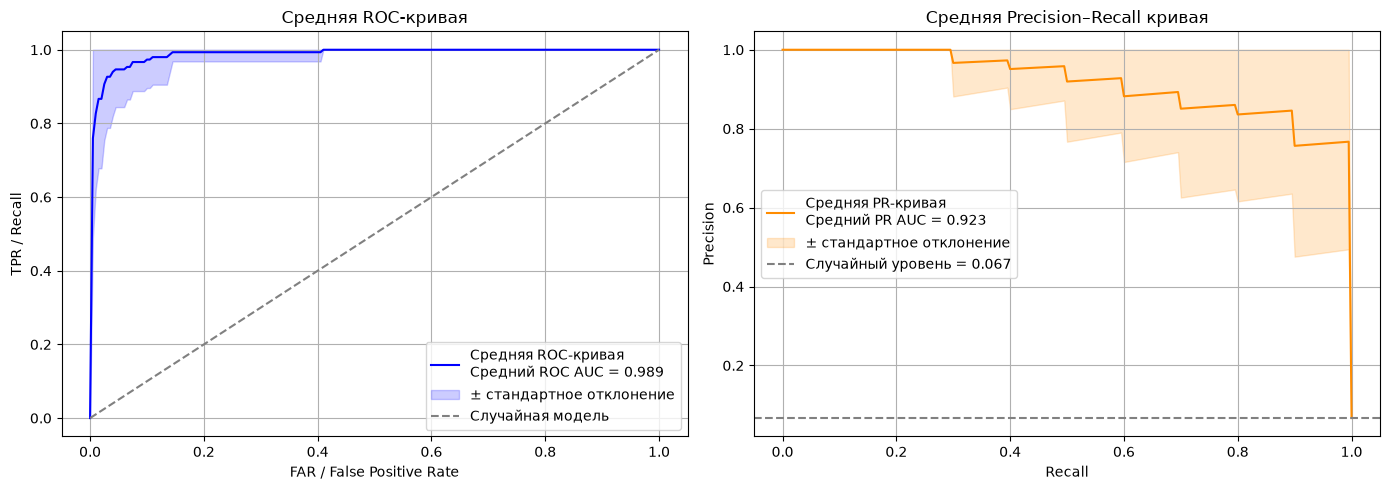

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,1.0000,1.0000,0.0000,0.0,0.0000,-0.1458,140,0,0,10
1,1,0.9857,0.8787,0.0929,0.1,0.0964,-0.3380,127,13,1,9
2,2,0.9964,0.9430,0.0071,0.0,0.0036,-0.2397,139,1,0,10
3,3,0.9186,0.6609,0.1857,0.2,0.1929,-0.3415,114,26,2,8
4,4,1.0000,1.0000,0.0000,0.0,0.0000,-0.2304,140,0,0,10
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.4164,140,0,0,10
6,6,1.0000,1.0000,0.0000,0.0,0.0000,-0.1407,140,0,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.4203,140,0,0,10
8,8,0.9714,0.7251,0.0643,0.0,0.0321,-0.4296,131,9,0,10
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.3744,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9890,0.0212,0.9979,0.9186,1.0000
PR_AUC,0.9248,0.1067,0.9733,0.6609,1.0000
FAR,0.0390,0.0586,0.0071,0.0000,0.1857
FRR,0.0267,0.0594,0.0000,0.0000,0.2000
EER,0.0329,0.0579,0.0036,0.0000,0.1929


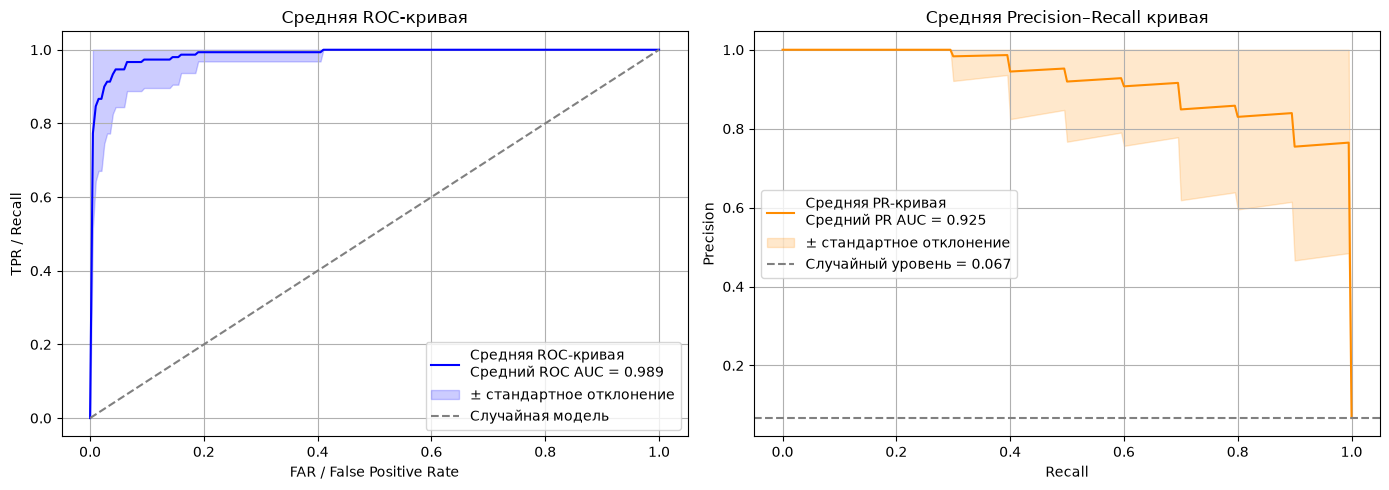

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,1.0000,1.0000,0.0000,0.0,0.0000,-0.1407,140,0,0,10
1,1,0.9843,0.8587,0.0929,0.1,0.0964,-0.3370,127,13,1,9
2,2,0.9971,0.9622,0.0143,0.0,0.0071,-0.2682,138,2,0,10
3,3,0.9143,0.6481,0.2143,0.2,0.2071,-0.3425,110,30,2,8
4,4,1.0000,1.0000,0.0000,0.0,0.0000,-0.2440,140,0,0,10
5,5,0.9929,0.9500,0.0714,0.1,0.0857,-0.4435,130,10,1,9
6,6,1.0000,1.0000,0.0000,0.0,0.0000,-0.1581,140,0,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.4071,140,0,0,10
8,8,0.9700,0.7198,0.0714,0.0,0.0357,-0.4395,130,10,0,10
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.3397,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9885,0.0221,0.9971,0.9143,1.0000
PR_AUC,0.9207,0.1089,0.9622,0.6481,1.0000
FAR,0.0429,0.0602,0.0143,0.0000,0.2143
FRR,0.0333,0.0617,0.0000,0.0000,0.2000
EER,0.0381,0.0599,0.0071,0.0000,0.2071


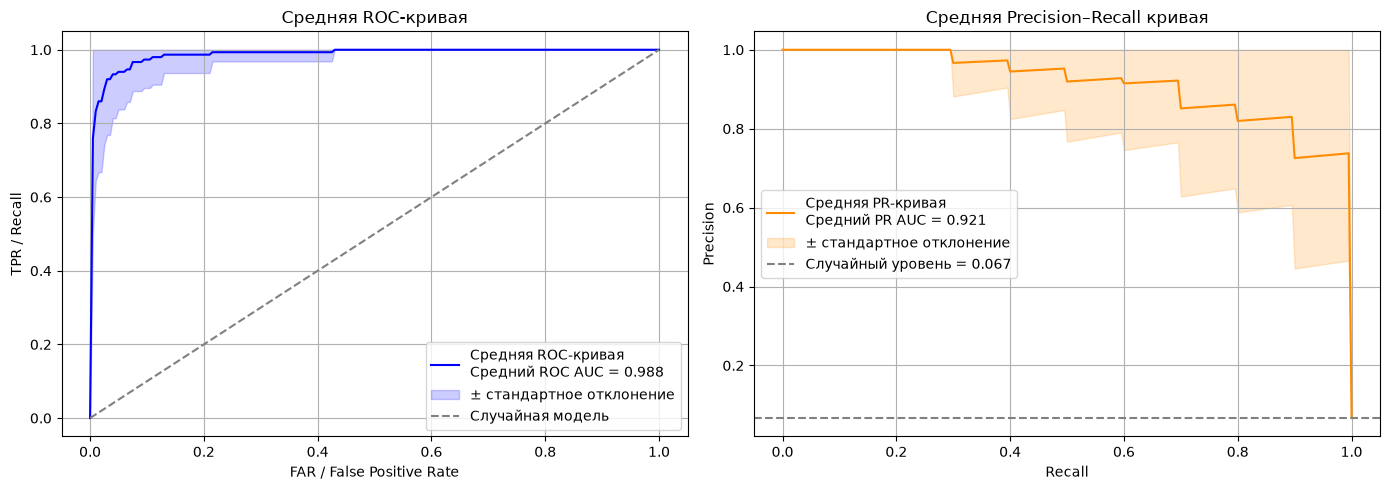

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.9921,0.9063,0.0357,0.0,0.0179,0.0043,135,5,0,10
1,1,0.9579,0.6783,0.0500,0.1,0.0750,-0.0052,133,7,1,9
2,2,0.9971,0.9622,0.0143,0.0,0.0071,0.0196,138,2,0,10
3,3,0.7586,0.4441,0.2786,0.3,0.2893,0.0173,101,39,3,7
4,4,1.0000,1.0000,0.0000,0.0,0.0000,0.0291,140,0,0,10
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.0529,140,0,0,10
6,6,1.0000,1.0000,0.0000,0.0,0.0000,0.0379,140,0,0,10
7,7,0.9993,0.9909,0.0071,0.0,0.0036,-0.0302,139,1,0,10
8,8,0.9464,0.5956,0.1000,0.1,0.1000,-0.0660,126,14,1,9
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.0443,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9700,0.0614,0.9921,0.7586,1.0000
PR_AUC,0.8637,0.1712,0.9063,0.4441,1.0000
FAR,0.0457,0.0719,0.0214,0.0000,0.2786
FRR,0.0533,0.0834,0.0000,0.0000,0.3000
EER,0.0495,0.0767,0.0107,0.0000,0.2893


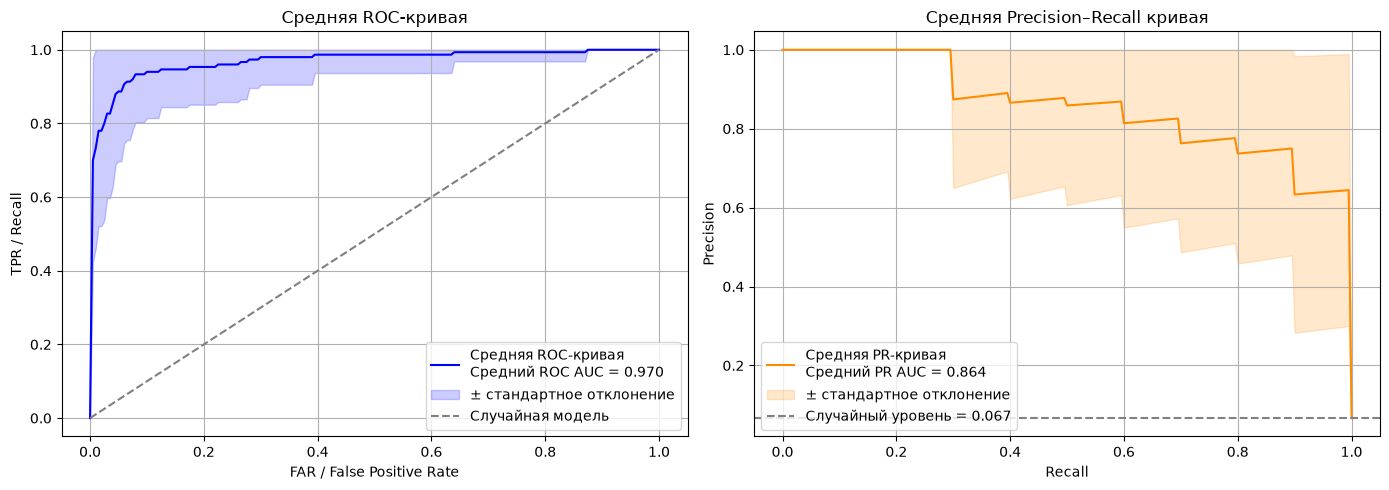

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.9943,0.9374,0.0357,0.0,0.0179,0.0075,135,5,0,10
1,1,0.9650,0.7374,0.0214,0.1,0.0607,0.0001,137,3,1,9
2,2,0.9971,0.9573,0.0071,0.0,0.0036,0.0284,139,1,0,10
3,3,0.7521,0.4751,0.2357,0.3,0.2679,0.0178,107,33,3,7
4,4,1.0000,1.0000,0.0000,0.0,0.0000,0.0165,140,0,0,10
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.0378,140,0,0,10
6,6,1.0000,1.0000,0.0000,0.0,0.0000,0.0680,140,0,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.0293,140,0,0,10
8,8,0.9471,0.6380,0.1143,0.1,0.1071,-0.0708,124,16,1,9
9,9,0.9986,0.9833,0.0143,0.0,0.0071,-0.0623,138,2,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9694,0.0631,0.9943,0.7521,1.0000
PR_AUC,0.8661,0.1594,0.9374,0.4751,1.0000
FAR,0.0495,0.0699,0.0214,0.0000,0.2357
FRR,0.0600,0.0910,0.0000,0.0000,0.3000
EER,0.0548,0.0795,0.0107,0.0000,0.2679


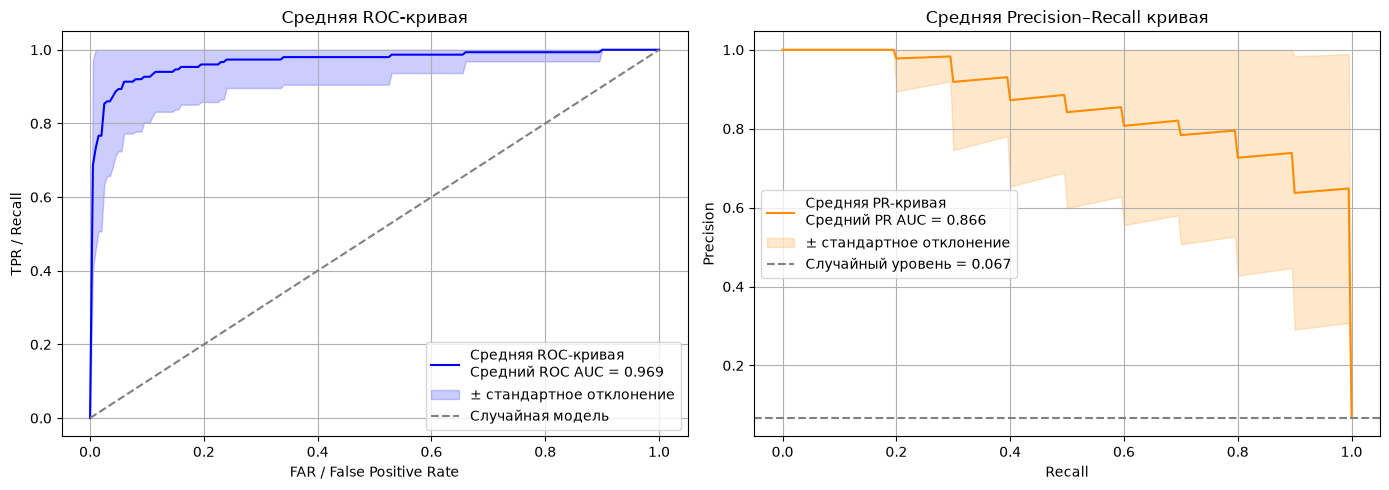

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.9893,0.8809,0.0571,0.1,0.0786,0.0048,132,8,1,9
1,1,0.9557,0.6768,0.0643,0.1,0.0821,-0.0066,131,9,1,9
2,2,0.9993,0.9909,0.0071,0.0,0.0036,0.0319,139,1,0,10
3,3,0.7250,0.4136,0.3071,0.3,0.3036,0.0150,97,43,3,7
4,4,1.0000,1.0000,0.0000,0.0,0.0000,0.0182,140,0,0,10
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.0429,140,0,0,10
6,6,1.0000,1.0000,0.0000,0.0,0.0000,0.0386,140,0,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.0298,140,0,0,10
8,8,0.9514,0.6093,0.0857,0.1,0.0929,-0.0713,128,12,1,9
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.0449,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9681,0.0699,0.9914,0.7250,1.0000
PR_AUC,0.8628,0.1778,0.8815,0.4136,1.0000
FAR,0.0529,0.0805,0.0214,0.0000,0.3071
FRR,0.0600,0.0828,0.0000,0.0000,0.3000
EER,0.0564,0.0810,0.0107,0.0000,0.3036


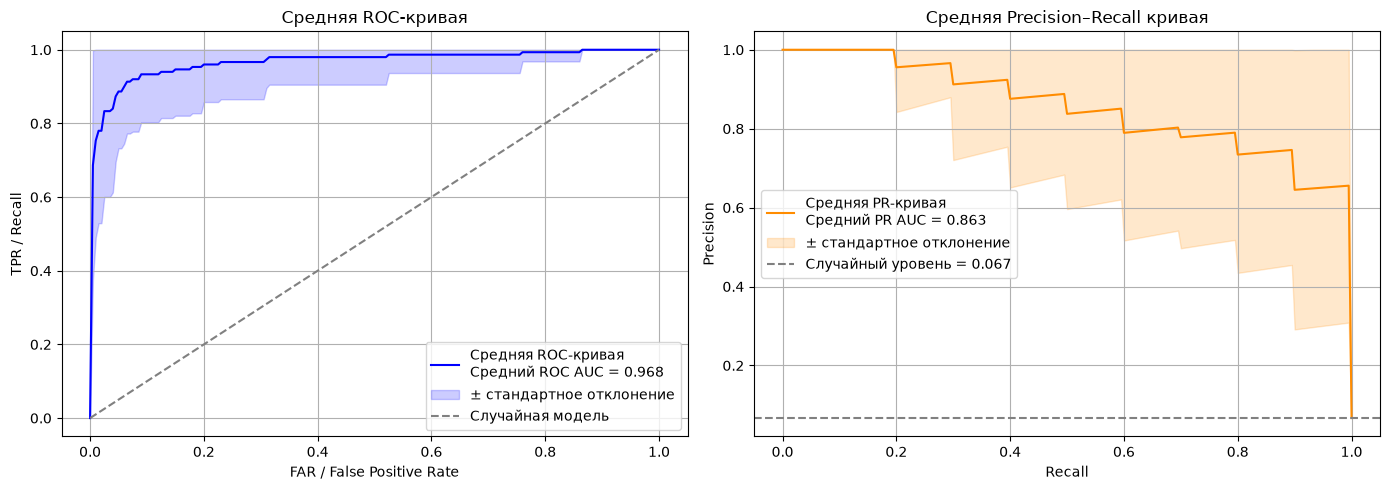

In [50]:
# функция загрузки фалидационных данных
def get_all_valid_test_features(user_folders, valid_test, filt):
    print("Загрузка валидационных данных в память...")
    all_valid_test_features = []
    for i in range(len(user_folders)):
        all_valid_test_features.append(get_user_features(user_folders, valid_test, num_user=i, filt=filt))
    return all_valid_test_features


# функция подсчета roc auc для одного пользователя
def get_roc_auc_for_one(user_folders, owner_user, X_train_scaled, scaler, all_valid_test_features, filt, model_id):
    # создаем объект model
    # через одноклассовую SVM
    if model_id == 1:
        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.1
        )

    # через изоляционный лес
    if model_id == 2:
        model = IsolationForest(
            n_estimators=200,
            contamination=0.1,
            random_state=1
        )
    
    # обучаем модеь на стандартизированных данных
    model.fit(X_train_scaled)

    # получаем векторы признаков владельца телефона
    X_owner = all_valid_test_features[owner_user]
    
    # получаем векторы признаков не-владельцев этого телефона
    impostor_features = [all_valid_test_features[i] for i in range(len(all_valid_test_features)) if i != owner_user]
    X_impostors = np.vstack(impostor_features)# кладем векторы друг на друга
    
    print(X_impostors.shape)
    print(X_owner.shape)
    
    # кладем таблички друг на друга
    X_valid_test = np.vstack([
        X_owner,
        X_impostors
    ])
    
    # получаем один вектор вида 111..1000...0 склеивая два вектора
    y_valid_test = np.concatenate([
        # создаем массив единичек
        np.ones(
            len(X_owner),
            dtype=int
        ),
        # создаем массив ноликов
        np.zeros(
            len(X_impostor),
            dtype=int
        )
    ])
    
    # проводим стандартизацию для валидационной выборки
    X_scaled = scaler.transform(X_valid_test)
    
    # считаем значения функции, кторая показывает насколько объект далек от границы, для новых данных
    scores = model.decision_function(X_scaled)
    
    # получаем roc auc, которая сравнивает реальные данные и значения функции дальности до границы
    roc_auc = roc_auc_score(y_valid_test, scores)
    print("ROC AUC for owner =", owner_user, ":", roc_auc)

    return roc_auc, X_scaled, y_valid_test

def evaluate_one_user(
    user_folders,
    all_valid_test_features,
    owner_user,
    mean_fpr_grid,
    mean_recall_grid,
    filt,
    model_id
):

    # получаем тренировочные жесты владельца
    X_train = get_user_features(
        user_folders,
        "train",
        num_user=owner_user,
        filt=filt
    )

    # cтандартизируем тренировочные признаки
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # обучаем отдельную модель владельца
    # через одноклассовую SVM
    if model_id == 1:
        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.1
        )

    # через изоляционный лес
    if model_id == 2:
        model = IsolationForest(
            n_estimators=200,
            contamination=0.1,
            random_state=1
        )
    model.fit(X_train_scaled)

    # получаем валидационныую выборку владельца
    X_owner = all_valid_test_features[owner_user]

    # собираем валидационную выборку посторонних (мошенников)
    impostor_matrices = []
    for user_index in range(len(user_folders)):
        if user_index == owner_user:
            continue
        impostor_matrices.append(all_valid_test_features[user_index])
    # кладем вектора признаков друг на друга (собираем их в матрицу)
    X_impostors = np.vstack(impostor_matrices)

    # cобираем общую валидационныую выборку
    X_valid_test = np.vstack([
        X_owner,
        X_impostors
    ])

    # получаем размеченный столбец для X_validation для того чтобы проверить метрики (0 - мошенник, 1 - владелец)
    y_valid_test = np.concatenate([
        np.ones(len(X_owner), dtype=int),
        np.zeros(len(X_impostors), dtype=int)
    ])

    # стандартизируем валидационную выборку (scaler обучен на тренировочной)
    X_scaled = scaler.transform(X_valid_test)

    # получаем оценки модели
    scores = model.decision_function(X_scaled)

    # ROC AUC и ROC-кривая
    roc_auc = roc_auc_score(y_valid_test, scores)
    fpr, tpr, roc_thresholds = roc_curve(y_valid_test, scores)
    far_values = fpr
    frr_values = 1 - tpr

    # находим EER и порог EER
    eer_index = np.argmin(np.abs(far_values - frr_values))
    eer_threshold = roc_thresholds[eer_index]
    eer = (far_values[eer_index] + frr_values[eer_index]) / 2

    # получаем итоговые предсказания
    y_pred = (scores >= eer_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    far = fp / (fp + tn)
    frr = fn / (fn + tp)


    # PR AUC и PR-кривая
    precision, recall, pr_thresholds = (
        precision_recall_curve(
            y_valid_test,
            scores
        )
    )

    pr_auc = average_precision_score(y_valid_test, scores)

    # результаты текущего пользователя
    metrics = {
        "user": owner_user,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "FAR": far,
        "FRR": frr,
        "EER": eer,
        "threshold": eer_threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    # интерполируем ROC-кривую
    interpolated_tpr = np.interp(mean_fpr_grid, fpr, tpr)
    interpolated_tpr[0] = 0

    # интерполируем PR-кривую
    # recall возвращается в убывающем порядке,
    # поэтому разворачиваем массивы.
    interpolated_precision = np.interp(
        mean_recall_grid,
        recall[::-1],
        precision[::-1]
    )

    curve_data = {
        "tpr": interpolated_tpr,
        "precision": interpolated_precision,
        "positive_rate": np.mean(y_valid_test)
    }

    return metrics, curve_data


def show_metrics_summary(metrics_table):

    print("Метрики всех пользователей:")
    display(metrics_table.round(4))

    metric_names = [
        "ROC_AUC",
        "PR_AUC",
        "FAR",
        "FRR",
        "EER"
    ]

    summary_table = metrics_table[metric_names].agg(["mean", "std", "median", "min", "max"]).T

    print("\nСводные показатели:")
    display(summary_table.round(4))

    return summary_table


def plot_mean_curves(curve_data_list, metrics_table, mean_fpr_grid, mean_recall_grid):

    # собираем данные всех ROC-кривых
    tpr_array = np.array([
        curve_data["tpr"]
        for curve_data in curve_data_list
    ])

    mean_tpr = np.mean(tpr_array, axis=0)
    std_tpr = np.std(tpr_array, axis=0)
    mean_tpr[-1] = 1

    # собираем данные всех PR-кривых
    precision_array = np.array([
        curve_data["precision"]
        for curve_data in curve_data_list
    ])

    mean_precision = np.mean(precision_array, axis=0)
    std_precision = np.std(precision_array, axis=0)

    mean_positive_rate = np.mean([
        curve_data["positive_rate"]
        for curve_data in curve_data_list
    ])

    # получаем средние AUC
    mean_roc_auc = metrics_table["ROC_AUC"].mean()
    mean_pr_auc = metrics_table["PR_AUC"].mean()

    # cоздаём два графика
    figure, axes = plt.subplots(1, 2, figsize=(14, 5))

    # средняя ROC-кривая
    axes[0].plot(
        mean_fpr_grid,
        mean_tpr,
        color="blue",
        label=(
            "Средняя ROC-кривая\n"
            f"Средний ROC AUC = "
            f"{mean_roc_auc:.3f}"
        )
    )

    axes[0].fill_between(
        mean_fpr_grid,
        np.maximum(mean_tpr - std_tpr,0),
        np.minimum(mean_tpr + std_tpr, 1),
        color="blue",
        alpha=0.2,
        label="± стандартное отклонение"
    )

    axes[0].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Случайная модель"
    )

    axes[0].set_xlabel("FAR / False Positive Rate")
    axes[0].set_ylabel("TPR / Recall")
    axes[0].set_title("Средняя ROC-кривая")
    axes[0].grid(True)
    axes[0].legend()

    # средняя PR-кривая
    axes[1].plot(
        mean_recall_grid,
        mean_precision,
        color="darkorange",
        label=(
            "Средняя PR-кривая\n"
            f"Средний PR AUC = "
            f"{mean_pr_auc:.3f}"
        )
    )

    axes[1].fill_between(
        mean_recall_grid,
        np.maximum(mean_precision - std_precision, 0),
        np.minimum(mean_precision + std_precision, 1),
        color="darkorange",
        alpha=0.2,
        label="± стандартное отклонение"
    )

    axes[1].axhline(
        mean_positive_rate,
        linestyle="--",
        color="gray",
        label=(
            "Случайный уровень = "
            f"{mean_positive_rate:.3f}"
        )
    )

    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Средняя Precision–Recall кривая")
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def run_all_users_analysis(user_folders, valid_test, filt, model_id):

    # сетки для усреднения кривых
    mean_fpr_grid = np.linspace(0, 1, 201)
    mean_recall_grid = np.linspace(0, 1, 201)

    # один раз читаем validation
    all_valid_test_features = get_all_valid_test_features(user_folders, valid_test, filt)

    metrics_rows = []
    curve_data_list = []
    
    # обучаем и проверяем модель каждого владельца
    for owner_user in range(len(user_folders)):

        metrics, curve_data = evaluate_one_user(
            user_folders=user_folders,
            all_valid_test_features=(all_valid_test_features),
            owner_user=owner_user,
            mean_fpr_grid=mean_fpr_grid,
            mean_recall_grid=(mean_recall_grid),
            filt=filt,
            model_id=model_id
        )

        metrics_rows.append(metrics)
        curve_data_list.append(curve_data)

    # создаём и выводим таблицу
    metrics_table = pd.DataFrame(metrics_rows)
    summary_table = show_metrics_summary(metrics_table)

    # строим средние кривые
    plot_mean_curves(
        curve_data_list=curve_data_list,
        metrics_table=metrics_table,
        mean_fpr_grid=mean_fpr_grid,
        mean_recall_grid=mean_recall_grid
    )

    return

# для валидационной выборки
run_all_users_analysis(user_folders, "valid", filt=0, model_id=1)
run_all_users_analysis(user_folders, "valid", filt=1, model_id=1)
run_all_users_analysis(user_folders, "valid", filt=2, model_id=1)
run_all_users_analysis(user_folders, "valid", filt=0, model_id=2)
run_all_users_analysis(user_folders, "valid", filt=1, model_id=2)
run_all_users_analysis(user_folders, "valid", filt=2, model_id=2)
# для тестовой
#metrics_table, summary_table = (run_all_users_analysis(user_folders, "test", filt=0, model_id=2))